# AIC 2026 — Sơ tuyển 3: CLIP retrieval + VLM phụ trợ

Nền tảng từ notebook P2. **Giữ nguyên** FAISS/CLIP ViT-B/32 và index BTC cho recall nhanh.
Bộ 36 query P3 dùng **prompt tiếng Anh ngắn đã duyệt thủ công**; Gemini chỉ là lớp verify tùy chọn.

### Thay đổi so với P2
1. **Tự động đọc và kiểm kê đúng 36 file**: 26 KIS, 8 QA, 2 TRAKE.
2. **Prompt bank Anh thủ công** tránh tiếng Việt yếu trên CLIP và tránh lỗi quá 77 token.
3. **Hybrid ranking** kết hợp CLIP, coverage, metadata, diversity và temporal rerank.
4. **VLM/OCR tùy chọn** để hỗ trợ verify; không làm batch phụ thuộc API key.
5. **FINAL_ROWS_OVERRIDE** dành cho frame đã nhìn thấy và xác minh.

### Cách dùng
1. Mở notebook bằng **Google Colab**, chọn GPU rồi **Runtime → Run all**.
2. Chờ dòng `BATCH P3 COMPLETE — 36 DRAFTS`; Gemini key không bắt buộc.
3. Review bằng các phần `# 13b`, `# 13c`; QA/TRAKE cần xem video ở `# 13d`.
4. Điền `# 14) CẤU HÌNH REVIEW P3`, chạy `# 15)` và nộp ZIP cuối **không giải nén**.

In [35]:
# 1) Cài thư viện — giữ CLIP ViT-B/32 + VLM phụ trợ
%pip install -q 'faiss-cpu==1.15.0' ftfy regex tqdm pillow matplotlib rapidfuzz remotezip pytesseract
%pip install -q 'git+https://github.com/openai/CLIP.git@dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1'
%pip install -q google-genai


  Preparing metadata (setup.py) ... done


In [36]:
# 2) Kết nối Drive và khai báo đường dẫn
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
from urllib.parse import parse_qsl, urlencode, urlsplit, urlunsplit
import csv
import hashlib
import io
import json
import os
import re
import shutil
import zipfile

import faiss
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from tqdm.auto import tqdm

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError('Hãy mở notebook bằng Google Colab.') from exc

drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/AIC2026')
RAW_DIR = DRIVE_ROOT / 'raw'
INDICES_DIR = DRIVE_ROOT / 'indices'
CANDIDATES_DIR = DRIVE_ROOT / 'candidates'
SUBMISSION_DIR = DRIVE_ROOT / 'submission'
MODELS_DIR = DRIVE_ROOT / 'models'
WORK_DIR = Path('/content/aic_work')
KEYFRAME_ZIP_DIR = DRIVE_ROOT / 'keyframe_zips'
ROUND_CANDIDATES_DIR = CANDIDATES_DIR / 'p3'
ROUND_SUBMISSION_ROOT = SUBMISSION_DIR / 'p3'
SELECTED_VIDEOS_DIR = DRIVE_ROOT / 'selected_videos'

for directory in (INDICES_DIR, ROUND_CANDIDATES_DIR, ROUND_SUBMISSION_ROOT, MODELS_DIR, SELECTED_VIDEOS_DIR, WORK_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CORE_ARCHIVES = {
    'features': {
        'filename': 'clip-features-32-aic25-b1.zip',
        'expected_bytes': 168_173_583,
        'outer': 'clip-features-32-aic25-b1',
        'inner': 'clip-features-32',
        'suffix': '.npy',
    },
    'maps': {
        'filename': 'map-keyframes-aic25-b1.zip',
        'expected_bytes': 1_604_272,
        'outer': 'map-keyframes-aic25-b1',
        'inner': 'map-keyframes',
        'suffix': '.csv',
    },
    'media': {
        'filename': 'media-info-aic25-b1.zip',
        'expected_bytes': 1_111_755,
        'outer': 'media-info-aic25-b1',
        'inner': 'media-info',
        'suffix': '.json',
    },
}

print('Drive:', DRIVE_ROOT)
print('Runtime:', WORK_DIR)
print('Device cho CLIP:', 'cuda' if torch.cuda.is_available() else 'cpu')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive: /content/drive/MyDrive/AIC2026
Runtime: /content/aic_work
Device cho CLIP: cpu


In [37]:
# 3) Khôi phục dữ liệu vào /content nếu Colab vừa khởi động lại
def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with open(path, 'rb') as file:
        while chunk := file.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

def safe_extract(zip_path, destination):
    destination.mkdir(parents=True, exist_ok=True)
    destination_root = destination.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        bad_member = archive.testzip()
        if bad_member is not None:
            raise RuntimeError(f'ZIP lỗi CRC tại: {bad_member}')
        for member in archive.infolist():
            member_path = (destination / member.filename).resolve()
            if member_path != destination_root and destination_root not in member_path.parents:
                raise RuntimeError(f'ZIP chứa đường dẫn không an toàn: {member.filename}')
        archive.extractall(destination)

def ensure_extracted(spec):
    drive_zip = RAW_DIR / spec['filename']
    if not drive_zip.is_file():
        raise FileNotFoundError(
            f'Thiếu {drive_zip}. Hãy chạy AIC_2026_Drive_Setup.ipynb trước.'
        )
    actual_size = drive_zip.stat().st_size
    if actual_size != spec['expected_bytes']:
        raise RuntimeError(
            f"Sai dung lượng {drive_zip.name}: {actual_size:,}; "
            f"cần {spec['expected_bytes']:,} bytes"
        )
    archive_sha256 = sha256_file(drive_zip)

    work_root = WORK_DIR.resolve()
    destination = (WORK_DIR / spec['outer']).resolve()
    if destination == work_root or work_root not in destination.parents:
        raise RuntimeError(f'Thư mục giải nén không an toàn: {destination}')
    inner_dir = destination / spec['inner']
    marker_path = destination / '.extract_complete.json'
    existing = list(inner_dir.glob(f"*{spec['suffix']}")) if inner_dir.is_dir() else []
    marker = {}
    if marker_path.is_file():
        try:
            with open(marker_path, encoding='utf-8') as file:
                marker = json.load(file)
        except (OSError, json.JSONDecodeError):
            marker = {}
    if (
        len(existing) == 873
        and marker.get('archive_sha256') == archive_sha256
        and marker.get('file_count') == 873
        and marker.get('suffix') == spec['suffix']
    ):
        print(f"✓ Tái sử dụng {len(existing)} file tại {inner_dir}")
        return inner_dir, archive_sha256

    local_zip = WORK_DIR / spec['filename']
    local_zip_valid = (
        local_zip.is_file()
        and local_zip.stat().st_size == actual_size
        and sha256_file(local_zip) == archive_sha256
    )
    if not local_zip_valid:
        print(f'→ Copy {drive_zip.name} xuống runtime...')
        shutil.copy2(drive_zip, local_zip)
    if destination.exists():
        print(f'→ Làm sạch cache giải nén cũ: {destination}')
        shutil.rmtree(destination)
    print(f'→ Giải nén {local_zip.name}...')
    safe_extract(local_zip, destination)

    extracted = list(inner_dir.glob(f"*{spec['suffix']}"))
    if len(extracted) != 873:
        raise RuntimeError(f'{inner_dir} chỉ có {len(extracted)} file; cần 873.')
    with open(marker_path, 'w', encoding='utf-8', newline='\n') as file:
        json.dump({
            'archive': spec['filename'],
            'archive_sha256': archive_sha256,
            'file_count': len(extracted),
            'suffix': spec['suffix'],
        }, file, ensure_ascii=False, indent=2)
    print(f'✓ Hoàn tất: {inner_dir}')
    return inner_dir, archive_sha256

FEATURE_DIR, feature_archive_sha = ensure_extracted(CORE_ARCHIVES['features'])
MAP_DIR, map_archive_sha = ensure_extracted(CORE_ARCHIVES['maps'])
MEDIA_DIR, media_archive_sha = ensure_extracted(CORE_ARCHIVES['media'])
EXTRACTED_ARCHIVE_HASHES = {
    'features': feature_archive_sha,
    'maps': map_archive_sha,
    'media': media_archive_sha,
}


✓ Tái sử dụng 873 file tại /content/aic_work/clip-features-32-aic25-b1/clip-features-32
✓ Tái sử dụng 873 file tại /content/aic_work/map-keyframes-aic25-b1/map-keyframes
✓ Tái sử dụng 873 file tại /content/aic_work/media-info-aic25-b1/media-info


In [38]:
# 4) Kiểm tra ba bộ file khớp tuyệt đối theo video_id
feature_files = {path.stem: path for path in FEATURE_DIR.glob('*.npy')}
map_files = {path.stem: path for path in MAP_DIR.glob('*.csv')}
media_files = {path.stem: path for path in MEDIA_DIR.glob('*.json')}

feature_ids = set(feature_files)
map_ids = set(map_files)
media_ids = set(media_files)
if feature_ids != map_ids or feature_ids != media_ids:
    raise RuntimeError(
        'Ba bộ dữ liệu không khớp video_id.\n'
        f'NPY thiếu so với tổng hợp: {sorted((map_ids | media_ids) - feature_ids)[:10]}\n'
        f'CSV thiếu: {sorted((feature_ids | media_ids) - map_ids)[:10]}\n'
        f'JSON thiếu: {sorted((feature_ids | map_ids) - media_ids)[:10]}'
    )
if len(feature_ids) != 873:
    raise RuntimeError(f'Tìm thấy {len(feature_ids)} video; bộ này phải có 873 video.')

VIDEO_IDS = sorted(feature_ids)

archive_hashes = dict(EXTRACTED_ARCHIVE_HASHES)
print('✓ Checksum ba ZIP nguồn đã được xác nhận cùng cache giải nén.')

source_lines = [
    f'{video_id}|{feature_files[video_id].stat().st_size}|'
    f'{map_files[video_id].stat().st_size}|{media_files[video_id].stat().st_size}'
    for video_id in VIDEO_IDS
]
source_lines += [f'archive|{key}|{archive_hashes[key]}' for key in sorted(archive_hashes)]
SOURCE_FINGERPRINT = hashlib.sha256('\n'.join(source_lines).encode('utf-8')).hexdigest()
group_counts = Counter(video_id.split('_', 1)[0] for video_id in VIDEO_IDS)

print(f'✓ {len(VIDEO_IDS)} video có đủ NPY + CSV + JSON')
print('Các nhóm:', dict(sorted(group_counts.items())))
print('Source fingerprint:', SOURCE_FINGERPRINT[:16] + '…')


✓ Checksum ba ZIP nguồn đã được xác nhận cùng cache giải nén.
✓ 873 video có đủ NPY + CSV + JSON
Các nhóm: {'L21': 29, 'L22': 31, 'L23': 25, 'L24': 43, 'L25': 88, 'L26': 498, 'L27': 16, 'L28': 24, 'L29': 23, 'L30': 96}
Source fingerprint: e8354abe69c43359…


In [39]:
# 5) Dựng hoặc tải lại exact cosine index
DIMENSION = 512
EXPECTED_VIDEOS = 873
CHUNK_ROWS = 32_768
BUNDLE_VERSION = 'aic25_b1_clip_vit_b32_ip_v1'
FORCE_REBUILD = False  # đổi thành True chỉ khi muốn dựng lại index

LOCAL_INDEX_DIR = WORK_DIR / 'indices'
LOCAL_INDEX_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_INDEX = LOCAL_INDEX_DIR / f'{BUNDLE_VERSION}.faiss'
LOCAL_FRAMES = LOCAL_INDEX_DIR / f'{BUNDLE_VERSION}_frames.csv.gz'
LOCAL_VIDEOS = LOCAL_INDEX_DIR / f'{BUNDLE_VERSION}_videos.csv'
LOCAL_MANIFEST = LOCAL_INDEX_DIR / f'{BUNDLE_VERSION}_manifest.json'
DRIVE_INDEX = INDICES_DIR / LOCAL_INDEX.name
DRIVE_FRAMES = INDICES_DIR / LOCAL_FRAMES.name
DRIVE_VIDEOS = INDICES_DIR / LOCAL_VIDEOS.name
DRIVE_MANIFEST = INDICES_DIR / LOCAL_MANIFEST.name

def numeric_integer_array(series, label):
    values = pd.to_numeric(series, errors='raise').to_numpy(dtype=np.float64)
    if not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
        raise ValueError(f'{label} phải gồm các số nguyên hữu hạn.')
    return values.astype(np.int64)

def validate_sources():
    required_columns = {'n', 'pts_time', 'fps', 'frame_idx'}
    total_rows = 0
    dtypes = set()
    row_counts = {}
    for video_id in tqdm(VIDEO_IDS, desc='Kiểm tra NPY ↔ CSV'):
        embeddings = np.load(feature_files[video_id], mmap_mode='r', allow_pickle=False)
        if embeddings.ndim != 2 or embeddings.shape[1] != DIMENSION:
            raise ValueError(f'{video_id}: shape NPY sai {embeddings.shape}; cần (N, 512).')
        if not np.issubdtype(embeddings.dtype, np.floating):
            raise TypeError(f'{video_id}: dtype NPY không phải số thực: {embeddings.dtype}')
        mapping = pd.read_csv(map_files[video_id])
        missing = required_columns - set(mapping.columns)
        if missing:
            raise ValueError(f'{video_id}: CSV thiếu cột {sorted(missing)}')
        if len(mapping) != embeddings.shape[0]:
            raise ValueError(
                f'{video_id}: NPY có {embeddings.shape[0]} dòng nhưng CSV có {len(mapping)} dòng.'
            )
        keyframe_n = numeric_integer_array(mapping['n'], f'{video_id}.n')
        frame_idx = numeric_integer_array(mapping['frame_idx'], f'{video_id}.frame_idx')
        pts_time = pd.to_numeric(mapping['pts_time'], errors='raise').to_numpy(dtype=np.float64)
        fps = pd.to_numeric(mapping['fps'], errors='raise').to_numpy(dtype=np.float64)
        if len(np.unique(keyframe_n)) != len(keyframe_n):
            raise ValueError(f'{video_id}: cột n bị trùng.')
        expected_n = np.arange(1, len(mapping) + 1, dtype=np.int64)
        if not np.array_equal(keyframe_n, expected_n):
            raise ValueError(f'{video_id}: cột n phải đúng 1..N theo thứ tự dòng NPY.')
        if np.any(np.diff(keyframe_n) < 0) or np.any(np.diff(frame_idx) < 0):
            raise ValueError(f'{video_id}: n hoặc frame_idx không tăng theo thứ tự dòng.')
        if np.any(frame_idx < 0):
            raise ValueError(f'{video_id}: frame_idx âm.')
        if not np.isfinite(pts_time).all() or np.any(pts_time < 0):
            raise ValueError(f'{video_id}: pts_time không hợp lệ.')
        if not np.isfinite(fps).all() or np.any(fps <= 0):
            raise ValueError(f'{video_id}: fps không hợp lệ.')
        row_counts[video_id] = int(embeddings.shape[0])
        total_rows += int(embeddings.shape[0])
        dtypes.add(str(embeddings.dtype))
    return total_rows, row_counts, sorted(dtypes)

def read_media_table():
    rows = []
    for video_id in VIDEO_IDS:
        with open(media_files[video_id], encoding='utf-8-sig') as file:
            info = json.load(file)
        rows.append({
            'video_id': video_id,
            'group': video_id.split('_', 1)[0],
            'title': info.get('title', ''),
            'author': info.get('author', ''),
            'length': info.get('length', ''),
            'watch_url': info.get('watch_url', ''),
        })
    return pd.DataFrame(rows)

def validate_loaded_bundle(index, frames, manifest, videos=None):
    if manifest.get('bundle_version') != BUNDLE_VERSION:
        raise ValueError('Sai bundle_version.')
    if manifest.get('source_fingerprint') != SOURCE_FINGERPRINT:
        raise ValueError('Index không được dựng từ đúng bộ dữ liệu hiện tại.')
    if manifest.get('source_archive_sha256') != archive_hashes:
        raise ValueError('Checksum ZIP nguồn trong manifest không khớp.')
    if manifest.get('model') != 'openai/CLIP ViT-B/32':
        raise ValueError('Sai model trong manifest.')
    if manifest.get('clip_commit') != 'dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1':
        raise ValueError('Sai CLIP commit trong manifest.')
    if manifest.get('metric') != 'inner_product_on_l2_normalized_vectors':
        raise ValueError('Sai metric trong manifest.')
    if manifest.get('dimension') != DIMENSION or not manifest.get('normalized'):
        raise ValueError('Sai dimension hoặc quy ước normalize trong manifest.')
    if index.d != DIMENSION or index.ntotal != len(frames):
        raise ValueError('Số chiều/số dòng giữa FAISS và metadata không khớp.')
    if manifest.get('total_vectors') != len(frames) or manifest.get('video_count') != EXPECTED_VIDEOS:
        raise ValueError('Số vector/video trong manifest không khớp.')
    required_frame_columns = {
        'faiss_id', 'video_id', 'group', 'npy_row',
        'keyframe_n', 'frame_idx', 'pts_time', 'fps',
    }
    missing_columns = required_frame_columns - set(frames.columns)
    if missing_columns:
        raise ValueError(f'Metadata frame thiếu cột: {sorted(missing_columns)}')
    expected_ids = np.arange(len(frames), dtype=np.int64)
    actual_ids = frames['faiss_id'].to_numpy(dtype=np.int64)
    if not np.array_equal(expected_ids, actual_ids):
        raise ValueError('faiss_id trong metadata không liên tục từ 0.')
    numeric_columns = ['keyframe_n', 'frame_idx', 'pts_time', 'fps']
    if not np.isfinite(frames[numeric_columns].to_numpy(dtype=np.float64)).all():
        raise ValueError('Metadata frame chứa NaN/Inf.')
    if videos is not None:
        if len(videos) != EXPECTED_VIDEOS or videos['video_id'].duplicated().any():
            raise ValueError('Metadata video thiếu hoặc trùng video_id.')
        if set(videos['video_id']) != set(VIDEO_IDS):
            raise ValueError('Danh sách video trong metadata không khớp nguồn.')

def load_bundle_from_drive():
    required = (DRIVE_INDEX, DRIVE_FRAMES, DRIVE_VIDEOS, DRIVE_MANIFEST)
    if not all(path.is_file() for path in required):
        return None
    with open(DRIVE_MANIFEST, encoding='utf-8') as file:
        manifest = json.load(file)
    if manifest.get('source_fingerprint') != SOURCE_FINGERPRINT:
        raise ValueError('Fingerprint nguồn đã thay đổi.')

    pairs = (
        (DRIVE_INDEX, LOCAL_INDEX, 'index'),
        (DRIVE_FRAMES, LOCAL_FRAMES, 'frames'),
        (DRIVE_VIDEOS, LOCAL_VIDEOS, 'videos'),
    )
    for drive_path, local_path, key in pairs:
        print(f'→ Copy {drive_path.name} xuống runtime...')
        shutil.copy2(drive_path, local_path)
        expected_hash = manifest['sha256'][key]
        if sha256_file(local_path) != expected_hash:
            raise ValueError(f'Checksum sai: {drive_path.name}')

    # Chỉ đọc FAISS sau khi checksum của file đã đúng.
    index = faiss.read_index(str(LOCAL_INDEX))
    frames = pd.read_csv(LOCAL_FRAMES)
    videos = pd.read_csv(LOCAL_VIDEOS, keep_default_na=False)
    validate_loaded_bundle(index, frames, manifest, videos)
    print(f'✓ Đã tải index: {index.ntotal:,} vector, {index.d} chiều')
    return index, frames, videos, manifest

def build_bundle():
    total_rows, row_counts, source_dtypes = validate_sources()
    estimated_mib = total_rows * DIMENSION * 4 / (1024 ** 2)
    print(f'Tổng keyframe embedding: {total_rows:,}')
    print(f'RAM/file index float32 ước tính: {estimated_mib:,.1f} MiB')

    index = faiss.IndexFlatIP(DIMENSION)
    frame_parts = []
    row_spans = []
    cursor = 0

    for video_id in tqdm(VIDEO_IDS, desc='Dựng FAISS exact index'):
        embeddings = np.load(feature_files[video_id], mmap_mode='r', allow_pickle=False)
        mapping = pd.read_csv(map_files[video_id])
        rows = len(mapping)
        start_id = cursor

        for start in range(0, rows, CHUNK_ROWS):
            end = min(start + CHUNK_ROWS, rows)
            block = np.ascontiguousarray(embeddings[start:end], dtype=np.float32)
            if not np.isfinite(block).all():
                raise ValueError(f'{video_id}: embedding chứa NaN/Inf.')
            norms = np.linalg.norm(block, axis=1)
            if np.any(norms <= 1e-12):
                raise ValueError(f'{video_id}: embedding có vector zero.')
            faiss.normalize_L2(block)
            index.add(block)

        keyframe_n = numeric_integer_array(mapping['n'], f'{video_id}.n')
        frame_idx = numeric_integer_array(mapping['frame_idx'], f'{video_id}.frame_idx')
        pts_time = pd.to_numeric(mapping['pts_time'], errors='raise').to_numpy(dtype=np.float64)
        fps = pd.to_numeric(mapping['fps'], errors='raise').to_numpy(dtype=np.float64)
        if not np.isfinite(pts_time).all() or not np.isfinite(fps).all():
            raise ValueError(f'{video_id}: pts_time/fps chứa NaN/Inf.')

        frame_parts.append(pd.DataFrame({
            'faiss_id': np.arange(cursor, cursor + rows, dtype=np.int64),
            'video_id': video_id,
            'group': video_id.split('_', 1)[0],
            'npy_row': np.arange(rows, dtype=np.int32),
            'keyframe_n': keyframe_n,
            'frame_idx': frame_idx,
            'pts_time': pts_time,
            'fps': fps,
        }))
        cursor += rows
        row_spans.append({
            'video_id': video_id,
            'start': start_id,
            'end': cursor,
            'rows': rows,
        })

    frames = pd.concat(frame_parts, ignore_index=True)
    videos = read_media_table()
    if index.ntotal != total_rows or len(frames) != total_rows:
        raise RuntimeError('Số vector và metadata không khớp sau khi build.')

    probe_ids = np.array([0, total_rows // 2, total_rows - 1], dtype=np.int64)
    probes = np.ascontiguousarray(
        np.vstack([index.reconstruct(int(item)) for item in probe_ids]),
        dtype=np.float32,
    )
    probe_scores, nearest = index.search(probes, 1)
    # Không bắt buộc ID trả về giống probe: hai frame có thể có vector trùng nhau.
    if np.any(nearest[:, 0] < 0) or not np.allclose(probe_scores[:, 0], 1.0, atol=1e-4):
        raise RuntimeError('Self-neighbor smoke test thất bại: cosine không gần 1.')

    faiss.write_index(index, str(LOCAL_INDEX))
    frames.to_csv(LOCAL_FRAMES, index=False, compression='gzip')
    videos.to_csv(LOCAL_VIDEOS, index=False, encoding='utf-8')
    manifest = {
        'bundle_version': BUNDLE_VERSION,
        'built_at_utc': datetime.now(timezone.utc).isoformat(),
        'model': 'openai/CLIP ViT-B/32',
        'clip_commit': 'dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1',
        'dimension': DIMENSION,
        'metric': 'inner_product_on_l2_normalized_vectors',
        'normalized': True,
        'index_dtype': 'float32',
        'source_dtypes': source_dtypes,
        'mapping_convention': 'NPY row i maps to CSV row i; n=i+1; submit frame_idx',
        'video_count': len(VIDEO_IDS),
        'total_vectors': total_rows,
        'source_fingerprint': SOURCE_FINGERPRINT,
        'source_archive_sha256': archive_hashes,
        'row_spans': row_spans,
        'versions': {
            'faiss': getattr(faiss, '__version__', 'unknown'),
            'numpy': np.__version__,
            'pandas': pd.__version__,
            'torch': torch.__version__,
        },
        'sha256': {
            'index': sha256_file(LOCAL_INDEX),
            'frames': sha256_file(LOCAL_FRAMES),
            'videos': sha256_file(LOCAL_VIDEOS),
        },
    }
    with open(LOCAL_MANIFEST, 'w', encoding='utf-8', newline='\n') as file:
        json.dump(manifest, file, ensure_ascii=False, indent=2)

    for local_path, drive_path in (
        (LOCAL_INDEX, DRIVE_INDEX),
        (LOCAL_FRAMES, DRIVE_FRAMES),
        (LOCAL_VIDEOS, DRIVE_VIDEOS),
    ):
        print(f'→ Lưu {local_path.name} lên Drive...')
        shutil.copy2(local_path, drive_path)
    # Manifest được ghi cuối cùng như dấu hiệu bundle đã hoàn tất.
    shutil.copy2(LOCAL_MANIFEST, DRIVE_MANIFEST)
    print(f'✓ Đã lưu bundle tại {INDICES_DIR}')
    return index, frames, videos, manifest

bundle = None
if not FORCE_REBUILD:
    try:
        bundle = load_bundle_from_drive()
    except Exception as exc:
        print(f'⚠ Không dùng được index đã lưu: {exc}')
        print('Sẽ dựng lại từ dữ liệu nguồn.')
if bundle is None:
    bundle = build_bundle()

index, frame_metadata, video_metadata, build_manifest = bundle
validate_loaded_bundle(index, frame_metadata, build_manifest, video_metadata)
print(f'READY: {index.ntotal:,} keyframes từ {len(video_metadata):,} video')


→ Copy aic25_b1_clip_vit_b32_ip_v1.faiss xuống runtime...
→ Copy aic25_b1_clip_vit_b32_ip_v1_frames.csv.gz xuống runtime...
→ Copy aic25_b1_clip_vit_b32_ip_v1_videos.csv xuống runtime...
✓ Đã tải index: 177,321 vector, 512 chiều
READY: 177,321 keyframes từ 873 video


## Ngân hàng truy vấn P3

Upload đề vào Colab rồi chạy cell 6.
Cell 7–8 dùng VLM dịch prompt. Cell 9 để kiểm tra/sửa.

In [40]:
# 6) Tự động đọc và phân loại query từ file đề
# ⚠ Upload thư mục đề thi vào Colab TRƯỚC khi chạy cell này.
# Cách 1: Upload lên Google Drive vào MyDrive/AIC2026/SOTUYEN3-bo-de-thi/
# Cách 2: Upload trực tiếp vào Colab runtime (cell sẽ hỏi nếu không tìm thấy).

import re

# Tìm thư mục query — thử nhiều đường dẫn
_CANDIDATE_DIRS = [
    DRIVE_ROOT / 'Questions/SOTUYEN3-bo-de-thi',
    Path.cwd() / 'SOTUYEN3-bo-de-thi',  # hỗ trợ kiểm tra notebook ngay trong workspace
    Path('/content/SOTUYEN3-bo-de-thi'),
    Path('/content/drive/MyDrive/SOTUYEN3-bo-de-thi'),
]
QUERY_DIR = None
for _d in _CANDIDATE_DIRS:
    if _d.is_dir() and list(_d.glob('query-*.txt')):
        QUERY_DIR = _d
        break

if QUERY_DIR is None:
    print('⚠ Chưa tìm thấy thư mục query. Upload file query:')
    from google.colab import files
    _uploaded = files.upload()
    _local = Path('/content/SOTUYEN3-bo-de-thi')
    _local.mkdir(parents=True, exist_ok=True)
    for _name, _data in _uploaded.items():
        (_local / _name).write_bytes(_data)
    QUERY_DIR = _local

QUERY_FILES = sorted(QUERY_DIR.glob('query-*.txt'))
print(f'✓ Tìm thấy {len(QUERY_FILES)} file query trong {QUERY_DIR}')

# ── Parse từng file ──
RAW_QUERIES = {}
for qf in QUERY_FILES:
    match = re.match(r'query-([\w]+-\d+)-(kis|qa|trake)\.txt', qf.name)
    if not match:
        print(f'  ⚠ Bỏ qua: {qf.name} (không khớp format)')
        continue
    qid = match.group(1)
    task = match.group(2)
    text = qf.read_text(encoding='utf-8').strip()

    query = {'task': task, 'query_vi': text, 'file': qf.name}

    if task == 'trake':
        lines = text.split('\n')
        description = lines[0].strip()
        events = {}
        for line in lines[1:]:
            ev = re.match(r'(E\d+)\s*:\s*(.*)', line.strip())
            if ev:
                events[ev.group(1)] = ev.group(2).strip()
        query['description'] = description
        query['events_vi'] = events

    elif task == 'qa':
        # Ưu tiên dòng cuối nếu đó là câu hỏi; hỗ trợ cả đề không có dấu '?'.
        nonempty_lines = [line.strip() for line in text.splitlines() if line.strip()]
        question_markers = (
            'hỏi ', 'hãy cho biết ', 'theo nội dung ', 'tác giả ',
            'trong quá trình ', 'dòng chữ ',
        )
        if len(nonempty_lines) > 1 and nonempty_lines[-1].lower().startswith(question_markers):
            query['question_vi'] = nonempty_lines[-1]
            query['description'] = '\n'.join(nonempty_lines[:-1]).strip()
        else:
            # File một dòng: lấy câu cuối từ marker đến hết, có hoặc không có '?'.
            marker_pattern = r'(?i)(hỏi|hãy cho biết|theo nội dung|tác giả|trong quá trình|dòng chữ)\b'
            matches = list(re.finditer(marker_pattern, text))
            if matches:
                start = matches[-1].start()
                query['question_vi'] = text[start:].strip()
                query['description'] = text[:start].strip()
            else:
                query['question_vi'] = text
                query['description'] = text

    RAW_QUERIES[qid] = query

# Sắp xếp theo số thứ tự
QUERY_IDS_ORDERED = sorted(RAW_QUERIES.keys(),
                           key=lambda x: int(x.split('-')[-1]))

# Tóm tắt
_counts = {}
for q in RAW_QUERIES.values():
    _counts[q['task']] = _counts.get(q['task'], 0) + 1
print(f'\nTổng: {len(RAW_QUERIES)} query — {_counts}')
for qid in QUERY_IDS_ORDERED:
    q = RAW_QUERIES[qid]
    preview = q['query_vi'][:80].replace('\n', ' ')
    extra = ''
    if q['task'] == 'qa':
        extra = f' | Hỏi: {q.get("question_vi", "")[:40]}'
    elif q['task'] == 'trake':
        extra = f' | {len(q.get("events_vi", {}))} events'
    print(f'  {qid:10s} [{q["task"]:5s}]{extra}  {preview}...')


✓ Tìm thấy 36 file query trong /content/drive/MyDrive/AIC2026/Questions/SOTUYEN3-bo-de-thi

Tổng: 36 query — {'kis': 26, 'qa': 8, 'trake': 2}
  p2-1       [kis  ]  Một chén trứng gà đã đánh tan được đổ vào nồi nước súp đang nấu. Trong nồi có cá...
  p2-2       [kis  ]  Một nhóm đông học sinh mặc đồng phục tập trung thành nhiều hàng trước khu vực tr...
  p2-3       [kis  ]  Người đầu bếp lần lượt cho nhiều loại nguyên liệu vào một nồi nước dùng đang sôi...
  p2-4       [kis  ]  Một giáo viên nữ ngồi bên phải màn hình và giảng bài Tiếng Anh. Trên bảng xanh l...
  p2-5       [qa   ] | Hỏi: Theo nội dung bài giảng, vùng được nhắc   Một giáo viên nam đứng bên trái màn hình giảng bài ôn tập môn Địa lí. Nội dung t...
  p2-6       [qa   ] | Hỏi: Tác giả được giới thiệu là người có duyê  Một giáo viên nam đứng bên trái màn hình và giảng bài trước một máy tính. Trên m...
  p2-7       [kis  ]  Đoạn phim ghi lại cảnh giao thông trên đường phố, trong đó hai thanh niên chạy x...
  p2-8       [qa   ]

In [41]:
# 7) Cấu hình VLM (Gemini) — TÙY CHỌN, không cần cho batch CLIP
# Pipeline P3 đã có prompt Anh thủ công ở cell 9 nên mặc định KHÔNG gọi API.
# Muốn dùng Gemini để verify top candidate: đặt GEMINI_API_KEY trong Colab
# Secrets rồi đổi ENABLE_VLM=True và chạy lại cell này.

import os

ENABLE_VLM = False
USE_VLM_FOR_TRANSLATION = False  # Giữ False: prompt P3 đã được duyệt thủ công.
VLM_ENABLED = False
vlm_client = None
VLM_MODEL = 'gemini-2.5-flash'

if ENABLE_VLM:
    try:
        from google import genai
        from google.genai import types as genai_types

        _key = os.environ.get('GEMINI_API_KEY', '').strip()
        if not _key:
            try:
                from google.colab import userdata
                _key = (userdata.get('GEMINI_API_KEY') or '').strip()
            except Exception as secret_error:
                print(f'⚠ Không đọc được Colab Secret: {secret_error}')

        if not _key:
            raise RuntimeError('Chưa có GEMINI_API_KEY.')

        vlm_client = genai.Client(api_key=_key)
        _resp = vlm_client.models.generate_content(
            model=VLM_MODEL,
            contents='Trả lời đúng một ký tự: 1+1=?',
        )
        VLM_ENABLED = True
        print(f'✓ VLM ({VLM_MODEL}) sẵn sàng. Test: {_resp.text.strip()}')
    except Exception as error:
        print(f'⚠ Không kích hoạt được VLM: {error}')
else:
    print('✓ Không gọi Gemini khi Run all; batch dùng prompt Anh P3 đã duyệt thủ công.')

if not VLM_ENABLED:
    print('→ CLIP/FAISS vẫn chạy đầy đủ. Cell 13e VLM verify sẽ tự bỏ qua.')


✓ Không gọi Gemini khi Run all; batch dùng prompt Anh P3 đã duyệt thủ công.
→ CLIP/FAISS vẫn chạy đầy đủ. Cell 13e VLM verify sẽ tự bỏ qua.


In [42]:
# 8) Dịch query Việt → prompt Anh cho CLIP bằng VLM
# VLM tạo bản nháp prompt, BẠN KIỂM TRA và sửa nếu cần.
# Nếu VLM tắt → bạn phải điền QUERY_BANK thủ công (cell tiếp theo).

import time

_TRANSLATE_SYSTEM = {
    'kis': """Bạn dịch mô tả video Việt → prompt Anh ngắn cho CLIP image search.
Tạo 2-4 prompt dưới 60 từ, mỗi prompt tập trung 1 khía cạnh thị giác (hành động, đối tượng, màu sắc, bối cảnh).
Trả lời JSON duy nhất, KHÔNG giải thích:
{"parts_en": ["prompt 1", "prompt 2"], "part_weights": [1.2, 1.0], "title_hints": ["từ_khóa_vi"], "temporal": true/false}
- part_weights: prompt quan trọng nhất 1.3-1.5, bổ trợ 0.8-1.0
- title_hints: 2-4 từ khóa Việt có thể xuất hiện trong tiêu đề video YouTube
- temporal: true nếu mô tả có trình tự thời gian""",

    'qa': """Bạn dịch mô tả video Việt → prompt Anh ngắn cho CLIP image search.
Tạo 2-3 prompt dưới 60 từ, mô tả cảnh chứa đáp án.
Trả lời JSON duy nhất:
{"parts_en": ["prompt 1"], "part_weights": [1.3], "title_hints": ["từ_khóa_vi"], "temporal": false, "review_mode": "manual_ocr_or_visual"}""",

    'trake': """Bạn dịch mô tả video TRAKE Việt → prompt Anh cho CLIP.
Tạo 2 prompt mô tả chung video + prompt cho từng event.
Trả lời JSON duy nhất:
{"parts_en": ["general desc"], "part_weights": [1.0], "title_hints": ["từ_khóa_vi"], "temporal": false, "events_en": {"E1": "event 1 in English", "E2": "..."}, "event_weights": [1.25, 1.25]}""",
}


def _vlm_translate_one(qid, raw):
    """Dịch 1 query bằng VLM. Trả về dict tương thích QUERY_BANK."""
    task = raw['task']
    user_msg = f"Vietnamese query:\n{raw['query_vi']}"
    if task == 'qa' and raw.get('question_vi'):
        user_msg += f"\n\nCâu hỏi: {raw['question_vi']}"
    if task == 'trake' and raw.get('events_vi'):
        user_msg += "\n\nSự kiện:\n" + "\n".join(
            f"{k}: {v}" for k, v in raw['events_vi'].items()
        )

    resp = vlm_client.models.generate_content(
        model=VLM_MODEL,
        contents=user_msg,
        config=genai_types.GenerateContentConfig(
            system_instruction=_TRANSLATE_SYSTEM[task],
            temperature=0.2,
        ),
    )

    text = resp.text.strip()
    # Xóa markdown code block nếu có
    if text.startswith('```'):
        text = re.sub(r'^```\w*\n?', '', text)
        text = re.sub(r'\n?```$', '', text)
        text = text.strip()

    result = json.loads(text)
    # Đảm bảo các trường bắt buộc
    result['task'] = task
    result['query_vi'] = raw['query_vi']
    if task == 'qa':
        result.setdefault('question_vi', raw.get('question_vi', ''))
        result.setdefault('review_mode', 'manual_ocr_or_visual')
    if task == 'trake':
        result.setdefault('events_vi', raw.get('events_vi', {}))
        if 'event_weights' not in result:
            result['event_weights'] = [1.25] * len(result.get('events_en', {}))
    result.setdefault('title_hints', [])
    result.setdefault('temporal', False)
    return result


def _short_fallback_prompt(value, max_words=28):
    # Chặn prompt dài theo từ; encode_texts còn có lớp bảo vệ theo CLIP token.
    words = str(value).replace('\n', ' ').split()
    return ' '.join(words[:int(max_words)]).strip()


def _make_fallback(raw):
    """Fallback an toàn token; prompt thủ công ở cell 9 sẽ thay thế cho đề P3."""
    visual_text = raw.get('description') or raw['query_vi']
    entry = {
        'task': raw['task'],
        'query_vi': raw['query_vi'],
        'parts_en': [_short_fallback_prompt(visual_text)],
        'part_weights': [1.0],
        'title_hints': [],
        'temporal': False,
    }
    if raw['task'] == 'qa':
        entry['question_vi'] = raw.get('question_vi', '')
        entry['review_mode'] = 'manual_ocr_or_visual'
    if raw['task'] == 'trake':
        events = raw.get('events_vi', {})
        entry['events_en'] = {k: _short_fallback_prompt(v, 24) for k, v in events.items()}
        entry['events_vi'] = events
        entry['event_weights'] = [1.0] * len(events)
    return entry


# ── Chạy dịch ──
QUERY_BANK = {}

if VLM_ENABLED and USE_VLM_FOR_TRANSLATION and RAW_QUERIES:
    print(f'→ Dịch {len(RAW_QUERIES)} query bằng {VLM_MODEL}...\n')
    for qid in QUERY_IDS_ORDERED:
        raw = RAW_QUERIES[qid]
        try:
            translated = _vlm_translate_one(qid, raw)
            QUERY_BANK[qid] = translated
            prompts = translated['parts_en']
            print(f'  ✓ {qid:10s} [{raw["task"]:5s}] {len(prompts)} prompts: {prompts[0][:60]}...')
            time.sleep(0.3)
        except Exception as e:
            print(f'  ✗ {qid:10s} lỗi VLM ({e}), dùng fallback')
            QUERY_BANK[qid] = _make_fallback(raw)
    print(f'\n✓ Đã dịch {len(QUERY_BANK)} query.')
elif RAW_QUERIES:
    print('→ Tạo query bank tạm; cell 9 sẽ áp prompt Anh P3 đã duyệt thủ công.')
    for qid in QUERY_IDS_ORDERED:
        QUERY_BANK[qid] = _make_fallback(RAW_QUERIES[qid])
else:
    print('⚠ Chưa có query. Download đề rồi chạy lại cell 6.')

print(f'\nQUERY_BANK có {len(QUERY_BANK)} entry.')


→ Tạo query bank tạm; cell 9 sẽ áp prompt Anh P3 đã duyệt thủ công.

QUERY_BANK có 36 entry.


In [43]:
# 9) PROMPT BANK P3 ĐÃ DUYỆT + VALIDATION
# Các ID chính thức của bộ Sơ tuyển 3 vẫn có prefix p2; KHÔNG đổi tên vì tên CSV
# nộp bài phải khớp chính xác tên query BTC cung cấp.
# Prompt ngắn, chỉ mô tả tín hiệu nhìn thấy để phù hợp CLIP ViT-B/32.

MANUAL_QUERY_OVERRIDES = {
    'p2-1': dict(parts_en=[
        'beaten egg poured into a soup pot with sliced mushrooms and bamboo shoots',
        'cook cuts tofu cubes directly above a soup pot and stirs the broth',
    ], part_weights=[1.15, 1.35], title_hints=['món súp', 'đậu hũ', 'trứng'], temporal=True),
    'p2-2': dict(parts_en=[
        'large rows of uniformed students outside a school holding class number signs',
        'students walk in long lines through a school corridor and up stairs',
    ], part_weights=[1.35, 1.05], title_hints=['học sinh', 'trường học'], temporal=True),
    'p2-3': dict(parts_en=[
        'cook adds vegetables mushrooms and sliced meat one by one into boiling broth',
        'close up of orange vegetables tube shaped ingredient greens brown mushrooms and meat in soup',
    ], part_weights=[1.25, 1.15], title_hints=['nấu canh', 'nước dùng'], temporal=True),
    'p2-4': dict(parts_en=[
        'female English teacher stands beside a green classroom board explaining grammar',
        'green board shows museum last week played football when young and grammar formulas',
    ], part_weights=[1.1, 1.4], title_hints=['Tiếng Anh', 'used to'], temporal=False),
    'p2-5': dict(parts_en=[
        'male geography teacher stands left of a large lecture screen',
        'Vietnam climate map and regional economics geography lesson slide',
    ], part_weights=[1.0, 1.4], title_hints=['Địa lí', 'vùng kinh tế'], temporal=False),
    'p2-6': dict(parts_en=[
        'male Vietnamese literature teacher beside a large lesson screen and computer',
        'literary essay structure and character analysis exam review slide',
    ], part_weights=[1.0, 1.35], title_hints=['Ngữ văn', 'nghị luận văn học', 'ôn thi'], temporal=False),
    'p2-7': dict(parts_en=[
        'two young men ride motorcycles recklessly in a car traffic lane',
        'motorcyclists weaving dangerously among cars on a busy road',
    ], part_weights=[1.2, 1.25], title_hints=['xe máy', 'giao thông'], temporal=False),
    'p2-8': dict(parts_en=[
        'male retro game collector interviewed among video game collectibles',
        'interview scene with a bright glowing neon text sign behind a man',
    ], part_weights=[1.15, 1.35], title_hints=['sưu tầm game', 'đồ chơi'], temporal=False),
    'p2-9': dict(parts_en=[
        'fashion models wear oversized cream outfits with colorful geometric patchwork',
        'outdoor textile art display with colorful handmade dolls balls and crafts',
    ], part_weights=[1.3, 1.1], title_hints=['thời trang', 'thổ cẩm'], temporal=False),
    'p2-10': dict(parts_en=[
        'vintage amphibious cars parade through a city canal under bridges',
        'crowds watch colorful classic cars driving like boats on water',
    ], part_weights=[1.4, 1.15], title_hints=['xe lội nước', 'diễu hành'], temporal=False),
    'p2-11': dict(parts_en=[
        'woman removes a white expanded stick cluster snack from a red kitchen appliance',
        'white puffed branching snack is placed on a clean white surface',
    ], part_weights=[1.4, 1.1], title_hints=['món ăn', 'máy đỏ'], temporal=True),
    'p2-12': dict(parts_en=[
        'white liquid is poured into a red frying pan while cooking',
        'cook tosses food in red and small pans as a bright pink flame rises',
    ], part_weights=[1.15, 1.35], title_hints=['chảo', 'ngọn lửa'], temporal=True),
    'p2-13': dict(parts_en=[
        'hundreds of woven bamboo fish traps stacked along a tropical riverbank',
        'traditional bamboo basket craft village beside Mekong boats and coconut trees',
    ], part_weights=[1.4, 1.2], title_hints=['lờ', 'lợp', 'làng nghề', 'Mekong'], temporal=False),
    'p2-14': dict(parts_en=[
        'young girl in a floral swimsuit is interviewed beside a swimming pool',
        'child swims in a pool wearing a purple swimming cap',
    ], part_weights=[1.25, 1.15], title_hints=['bé gái', 'bơi'], temporal=False),
    'p2-15': dict(parts_en=[
        'food is rinsed drained and coated in batter by hand',
        'green leaf and two yellow food pieces fry in a red pan',
    ], part_weights=[1.1, 1.4], title_hints=['chiên', 'chảo đỏ'], temporal=True),
    'p2-16': dict(parts_en=[
        'ingredients in a clear glass pot with red and green mixture being stirred',
        'cook adds a large measured bottle of liquid salt sugar and stock seasoning',
    ], part_weights=[1.2, 1.2], title_hints=['nấu ăn', '1.5 lít'], temporal=True),
    'p2-17': dict(parts_en=[
        'fried food is cut in half but remains attached on a cutting board',
        'cook separates the core and shell with a small tool then places it on a white utensil',
    ], part_weights=[1.2, 1.35], title_hints=['món chiên'], temporal=True),
    'p2-18': dict(parts_en=[
        'nun gently helps a boy in a green shirt studying in a classroom',
        'female teacher wearing pink teaches while children write mathematics in notebooks',
    ], part_weights=[1.35, 1.15], title_hints=['sư cô', 'lớp học', 'tiểu học'], temporal=False),
    'p2-19': dict(parts_en=[
        'yellow lion dance costume balances high on metal poles',
        'lion dancer bites a purple flower and opens its jaw in rhythm',
    ], part_weights=[1.35, 1.2], title_hints=['múa lân', 'mai hoa thung'], temporal=True),
    'p2-20': dict(parts_en=[
        'Vietnamese chemistry lecture slide about organic compounds and grain variants',
        'molecule classification diagram with long circles and purple cross links on a presentation',
    ], part_weights=[1.2, 1.3], title_hints=['hợp chất hữu cơ', 'hóa học'], temporal=False),
    'p2-21': dict(parts_en=[
        'chef cooks shrimp with orange juice orange zest sauce and spices',
        'plated shrimp dish decorated with several orange wedges',
    ], part_weights=[1.25, 1.2], title_hints=['tôm', 'cam'], temporal=False,
    events_en={
        'E1': 'chef begins mixing a sauce containing orange juice and orange zest',
        'E2': 'chef begins cutting the head off a shrimp',
        'E3': 'the first cooked shrimp touches the serving plate',
        'E4': 'the fourth orange segment is placed on the plated shrimp dish',
    }, event_weights=[1.2, 1.3, 1.35, 1.35]),
    'p2-22': dict(parts_en=[
        'electric aerial vehicle with a large circular upper frame flying above gardens',
        'futuristic passenger drone over geometric gardens and a historic European estate',
    ], part_weights=[1.4, 1.25], title_hints=['taxi bay', 'máy bay điện'], temporal=False),
    'p2-23': dict(parts_en=[
        'three pairs of water buffalo race through a muddy field in Southeast Asia',
        'white water buffalo pair running through mud with riders and spectators',
    ], part_weights=[1.35, 1.2], title_hints=['đua trâu'], temporal=False),
    'p2-24': dict(parts_en=[
        'cook prepares an orange salmon fillet and chops herbs and peppercorns',
        'spice mixture is spread on both sides of salmon before pouring soy sauce',
    ], part_weights=[1.25, 1.35], title_hints=['cá hồi', 'nước tương'], temporal=False),
    'p2-25': dict(parts_en=[
        'ladle dips thin sliced meat into a pot of boiling broth',
        'cooked meat is placed over white noodles and tomato then broth is poured into bowl',
    ], part_weights=[1.25, 1.4], title_hints=['mì', 'nước dùng', 'thịt'], temporal=True),
    'p2-26': dict(parts_en=[
        'geometry lecture slide with a slanted line passing through a plane',
        'intersecting planes perpendicular segments and tetrahedron diagrams with dashed lines',
    ], part_weights=[1.15, 1.4], title_hints=['hình học', 'đường thẳng', 'mặt phẳng'], temporal=False),
    'p2-27': dict(parts_en=[
        'two people flatten white and colored dough and place filling in the center',
        'colored stuffed dough pieces are wrapped placed on small leaves then arranged on a plate',
    ], part_weights=[1.25, 1.3], title_hints=['bột', 'bánh'], temporal=False),
    'p2-28': dict(parts_en=[
        'woman with black frame glasses is interviewed while holding a white donation bag',
        'white clothing donation bag with a green logo held toward the camera',
    ], part_weights=[1.25, 1.4], title_hints=['quyên góp', 'quần áo'], temporal=False),
    'p2-29': dict(parts_en=[
        'person ladles soup from a cooking pot into a smaller bowl',
        'small soup bowl sits on striped cloth and a wooden serving tray',
    ], part_weights=[1.4, 1.1], title_hints=['múc canh', 'múc súp'], temporal=True),
    'p2-30': dict(parts_en=[
        'cyclist crosses a finish line beside a race flag',
        'large road cycling peloton turns onto a shaded street as spectators film',
    ], part_weights=[1.15, 1.35], title_hints=['đua xe đạp'], temporal=True),
    'p2-31': dict(parts_en=[
        'blond foreign young man sits cross legged with local people wrapping leaf cakes',
        'group makes traditional green leaf cakes beside a green electric fan',
    ], part_weights=[1.3, 1.2], title_hints=['gói bánh', 'người nước ngoài'], temporal=False),
    'p2-32': dict(parts_en=[
        'mother and child talk together while looking at a mobile phone',
        'child is interviewed as a woman in black walks behind',
    ], part_weights=[1.15, 1.3], title_hints=['mẹ và bé', 'phỏng vấn'], temporal=True),
    'p2-33': dict(parts_en=[
        'slow motion aerial view of two road cyclists sprinting side by side',
        'cyclist in black helmet loses a sprint to cyclist in white helmet',
    ], part_weights=[1.25, 1.35], title_hints=['nước rút', 'xe đạp'], temporal=False),
    'p2-34': dict(parts_en=[
        'red lion dance costume performs acrobatics on a row of tall metal poles',
        'red lion dancer balances turns and grips poles high above the ground',
    ], part_weights=[1.4, 1.2], title_hints=['múa lân', 'mai hoa thung'], temporal=False,
    events_en={
        'E1': 'red lion hangs both front legs below the bodies of two poles near the highest final pole',
        'E2': 'red lion stands across two poles with one front leg raised',
        'E3': 'red lion finishes turning its face in the opposite direction',
        'E4': 'first moment the red lion bites or grips a pole with its mouth',
    }, event_weights=[1.3, 1.3, 1.2, 1.3]),
    'p2-35': dict(parts_en=[
        'Vietnamese high school national exam 2018 multiple choice math solution slide',
        'four questions labeled as one group with answers A B C D containing digit zero',
    ], part_weights=[1.2, 1.4], title_hints=['THPTQG 2018', 'giải đề', 'nhóm'], temporal=False),
    'p2-36': dict(parts_en=[
        'slow camera pan across a desk with an old photograph of a person shaking hands with Ho Chi Minh',
        'artisan redraws a portrait from the photograph using a special pen and material',
    ], part_weights=[1.35, 1.25], title_hints=['Hồ Chí Minh', 'vẽ chân dung'], temporal=True),
}

QA_QUESTION_OVERRIDES = {
    'p2-5': 'Theo nội dung bài giảng, vùng được nhắc đến gồm bao nhiêu tỉnh, thành?',
    'p2-6': 'Tác giả được giới thiệu gắn bó với đề tài miền núi nào?',
    'p2-8': 'Dòng chữ neon phát sáng là gì?',
    'p2-14': 'Bé gái sắp lên học lớp mấy?',
    'p2-18': 'Các giáo viên tham gia giảng dạy là giáo viên chính ở trường tiểu học nào?',
    'p2-24': 'Lượng nước tương được sử dụng là bao nhiêu?',
    'p2-27': 'Trên đĩa có mấy màu bột khác nhau?',
    'p2-35': 'X là số mấy?',
}

if set(MANUAL_QUERY_OVERRIDES) != set(QUERY_IDS_ORDERED):
    missing = sorted(set(QUERY_IDS_ORDERED) - set(MANUAL_QUERY_OVERRIDES))
    extra = sorted(set(MANUAL_QUERY_OVERRIDES) - set(QUERY_IDS_ORDERED))
    raise RuntimeError(f'Prompt bank không khớp đề P3; thiếu={missing}, thừa={extra}')

for query_id in QUERY_IDS_ORDERED:
    QUERY_BANK[query_id].update(MANUAL_QUERY_OVERRIDES[query_id])
    if query_id in QA_QUESTION_OVERRIDES:
        QUERY_BANK[query_id]['question_vi'] = QA_QUESTION_OVERRIDES[query_id]
        QUERY_BANK[query_id]['review_mode'] = 'manual_ocr_or_visual'
    if QUERY_BANK[query_id]['task'] == 'trake':
        QUERY_BANK[query_id]['events_vi'] = RAW_QUERIES[query_id].get('events_vi', {})

EXPECTED_QUERY_COUNT = 36
EXPECTED_TASK_COUNTS = {'kis': 26, 'qa': 8, 'trake': 2}
query_numbers = [int(query_id.rsplit('-', 1)[1]) for query_id in QUERY_IDS_ORDERED]
actual_task_counts = {
    task: sum(q['task'] == task for q in QUERY_BANK.values())
    for task in EXPECTED_TASK_COUNTS
}
if len(QUERY_BANK) != EXPECTED_QUERY_COUNT or query_numbers != list(range(1, 37)):
    raise RuntimeError(f'Inventory P3 sai: count={len(QUERY_BANK)}, IDs={query_numbers}')
if actual_task_counts != EXPECTED_TASK_COUNTS:
    raise RuntimeError(f'Loại query P3 sai: {actual_task_counts}')

for query_id in QUERY_IDS_ORDERED:
    config = QUERY_BANK[query_id]
    raw = RAW_QUERIES[query_id]
    if config['task'] != raw['task']:
        raise RuntimeError(f'{query_id}: task không khớp file đề')
    prompts = config.get('parts_en', [])
    weights = config.get('part_weights', [])
    if not prompts or len(prompts) != len(weights):
        raise RuntimeError(f'{query_id}: parts_en/part_weights không hợp lệ')
    if any(not str(prompt).strip() for prompt in prompts):
        raise RuntimeError(f'{query_id}: prompt rỗng')
    if any(not np.isfinite(float(weight)) or float(weight) <= 0 for weight in weights):
        raise RuntimeError(f'{query_id}: trọng số prompt không hợp lệ')
    if config['task'] == 'qa' and not config.get('question_vi', '').strip():
        raise RuntimeError(f'{query_id}: thiếu question_vi')
    if config['task'] == 'trake':
        events_en = config.get('events_en', {})
        events_vi = raw.get('events_vi', {})
        event_weights = config.get('event_weights', [])
        if list(events_en) != list(events_vi) or len(events_en) != len(event_weights):
            raise RuntimeError(f'{query_id}: events/trọng số không khớp thứ tự đề')

print('═' * 76)
print('✓ PROMPT BANK P3: 36/36 câu — 26 KIS, 8 QA, 2 TRAKE')
print('✓ Prefix p2 là tên CHÍNH THỨC trong đề Sơ tuyển 3; giữ nguyên khi nộp.')
print('═' * 76)
for query_id in QUERY_IDS_ORDERED:
    config = QUERY_BANK[query_id]
    print(f'\n{query_id} [{config["task"]}] | {RAW_QUERIES[query_id]["file"]}')
    for prompt_number, (prompt, weight) in enumerate(zip(config['parts_en'], config['part_weights']), 1):
        print(f'  P{prompt_number} (w={float(weight):.2f}): {prompt}')
    if config.get('title_hints'):
        print(f'  Title: {config["title_hints"]}')
    if config['task'] == 'qa':
        print(f'  QA: {config["question_vi"]}')
    if config['task'] == 'trake':
        for event_name, event_prompt in config['events_en'].items():
            print(f'  {event_name}: {event_prompt}')


════════════════════════════════════════════════════════════════════════════
✓ PROMPT BANK P3: 36/36 câu — 26 KIS, 8 QA, 2 TRAKE
✓ Prefix p2 là tên CHÍNH THỨC trong đề Sơ tuyển 3; giữ nguyên khi nộp.
════════════════════════════════════════════════════════════════════════════

p2-1 [kis] | query-p2-1-kis.txt
  P1 (w=1.15): beaten egg poured into a soup pot with sliced mushrooms and bamboo shoots
  P2 (w=1.35): cook cuts tofu cubes directly above a soup pot and stirs the broth
  Title: ['món súp', 'đậu hũ', 'trứng']

p2-2 [kis] | query-p2-2-kis.txt
  P1 (w=1.35): large rows of uniformed students outside a school holding class number signs
  P2 (w=1.05): students walk in long lines through a school corridor and up stairs
  Title: ['học sinh', 'trường học']

p2-3 [kis] | query-p2-3-kis.txt
  P1 (w=1.25): cook adds vegetables mushrooms and sliced meat one by one into boiling broth
  P2 (w=1.15): close up of orange vegetables tube shaped ingredient greens brown mushrooms and meat in soup
  

In [44]:
# 7) Nạp text encoder tương thích với embedding ảnh
import clip

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
LOCAL_MODELS_DIR = WORK_DIR / 'models'
LOCAL_MODELS_DIR.mkdir(parents=True, exist_ok=True)
CLIP_CHECKPOINT_NAME = 'ViT-B-32.pt'
CLIP_CHECKPOINT_SHA256 = '40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af'
drive_checkpoint = MODELS_DIR / CLIP_CHECKPOINT_NAME
local_checkpoint = LOCAL_MODELS_DIR / CLIP_CHECKPOINT_NAME
drive_checkpoint_valid = (
    drive_checkpoint.is_file()
    and sha256_file(drive_checkpoint) == CLIP_CHECKPOINT_SHA256
)
if drive_checkpoint_valid and not local_checkpoint.is_file():
    print('→ Copy checkpoint CLIP từ Drive xuống runtime...')
    shutil.copy2(drive_checkpoint, local_checkpoint)
elif drive_checkpoint.is_file() and not drive_checkpoint_valid:
    print('⚠ Checkpoint CLIP trên Drive sai checksum; sẽ tải lại bản chuẩn.')

clip_model, _ = clip.load(
    'ViT-B/32',
    device=DEVICE,
    jit=False,
    download_root=str(LOCAL_MODELS_DIR),
)
clip_model.eval()
if sha256_file(local_checkpoint) != CLIP_CHECKPOINT_SHA256:
    raise RuntimeError('Checkpoint CLIP sau khi tải vẫn sai checksum.')
if not drive_checkpoint_valid:
    print('→ Lưu checkpoint CLIP hoàn chỉnh lên Drive...')
    shutil.copy2(local_checkpoint, drive_checkpoint)

def tokenize_texts_safely(prompts):
    """Tokenize từng prompt; chỉ truncate prompt vượt giới hạn và luôn cảnh báo."""
    token_rows = []
    truncated = []
    for index, prompt in enumerate(prompts):
        try:
            row = clip.tokenize([prompt], truncate=False)
        except RuntimeError:
            row = clip.tokenize([prompt], truncate=True)
            truncated.append((index, prompt))
        token_rows.append(row)
    if truncated:
        print(f'⚠ CLIP đã cắt {len(truncated)} prompt vượt 77 token (batch vẫn tiếp tục):')
        for index, prompt in truncated[:10]:
            print(f'  [{index}] {prompt[:140]}')
        if len(truncated) > 10:
            print(f'  ... và {len(truncated) - 10} prompt khác')
    return torch.cat(token_rows, dim=0)

def encode_texts(prompts):
    if isinstance(prompts, str):
        prompts = [prompts]
    prompts = [str(item).strip() for item in prompts]
    if not prompts or any(not item for item in prompts):
        raise ValueError('Prompt không được rỗng.')
    tokens = tokenize_texts_safely(prompts).to(DEVICE)
    with torch.inference_mode():
        vectors = clip_model.encode_text(tokens).float()
        vectors = vectors / vectors.norm(dim=-1, keepdim=True).clamp_min(1e-12)
    output = np.ascontiguousarray(vectors.cpu().numpy(), dtype=np.float32)
    if output.shape != (len(prompts), DIMENSION) or not np.isfinite(output).all():
        raise RuntimeError(f'Text embedding không hợp lệ: {output.shape}')
    return output

all_configured_prompts = []
for query_id in QUERY_IDS_ORDERED:
    config = QUERY_BANK[query_id]
    all_configured_prompts.extend(config['parts_en'])
    all_configured_prompts.extend(config.get('events_en', {}).values())
_token_test = tokenize_texts_safely(all_configured_prompts)
if _token_test.shape != (len(all_configured_prompts), 77):
    raise RuntimeError(f'Token matrix P3 không hợp lệ: {_token_test.shape}')

test_vector = encode_texts(['a video frame'])
print(f'✓ CLIP ViT-B/32 trên {DEVICE}: shape={test_vector.shape}')
print(f'✓ Đã kiểm tra token cho {len(all_configured_prompts)} prompt P3.')


✓ CLIP ViT-B/32 trên cpu: shape=(1, 512)
✓ Đã kiểm tra token cho 80 prompt P3.


In [45]:
# 8) Hàm tìm frame, xếp hạng video và tìm riêng trong một video
def search_prompts_global(prompts, per_prompt_k=5000):
    prompts = [prompts] if isinstance(prompts, str) else list(prompts)
    if not prompts:
        raise ValueError('Cần ít nhất một prompt.')
    query_vectors = encode_texts(prompts)
    k = min(int(per_prompt_k), int(index.ntotal))
    if k <= 0:
        raise ValueError('per_prompt_k phải lớn hơn 0.')
    scores, ids = index.search(query_vectors, k)
    parts = []
    for part_index, prompt in enumerate(prompts):
        valid = ids[part_index] >= 0
        selected_ids = ids[part_index][valid].astype(np.int64)
        selected = frame_metadata.iloc[selected_ids].copy()
        selected.insert(0, 'part_index', part_index)
        selected.insert(1, 'prompt', prompt)
        selected.insert(2, 'score', scores[part_index][valid].astype(np.float32))
        parts.append(selected)
    return pd.concat(parts, ignore_index=True)

def rank_videos_for_parts(prompts, per_prompt_k=5000, top_videos=50):
    prompts = [prompts] if isinstance(prompts, str) else list(prompts)
    if not prompts or int(top_videos) <= 0:
        raise ValueError('Prompts không rỗng và top_videos phải lớn hơn 0.')
    hits = search_prompts_global(prompts, per_prompt_k=per_prompt_k)
    best = (
        hits.sort_values(
            ['part_index', 'score', 'video_id', 'frame_idx'],
            ascending=[True, False, True, True],
        )
        .drop_duplicates(['part_index', 'video_id'], keep='first')
    )
    score_wide = best.pivot(index='video_id', columns='part_index', values='score')
    for part_index in range(len(prompts)):
        if part_index not in score_wide.columns:
            score_wide[part_index] = np.nan
    score_wide = score_wide[range(len(prompts))]
    matched = score_wide.notna().sum(axis=1)
    filled = score_wide.copy()
    for part_index in range(len(prompts)):
        column = filled[part_index]
        floor = float(column.min()) - 0.01 if column.notna().any() else -1.0
        filled[part_index] = column.fillna(floor)

    ranking = pd.DataFrame({
        'video_id': score_wide.index,
        'parts_matched': matched.to_numpy(dtype=np.int32),
        'parts_total': len(prompts),
        'coverage_score': filled.mean(axis=1).to_numpy(dtype=np.float32),
        'worst_part_score': filled.min(axis=1).to_numpy(dtype=np.float32),
        'best_score': score_wide.max(axis=1).to_numpy(dtype=np.float32),
    })

    for part_index in range(len(prompts)):
        part_best = best[best['part_index'] == part_index][
            ['video_id', 'score', 'keyframe_n', 'frame_idx', 'pts_time']
        ].rename(columns={
            'score': f'p{part_index + 1}_score',
            'keyframe_n': f'p{part_index + 1}_keyframe_n',
            'frame_idx': f'p{part_index + 1}_frame_idx',
            'pts_time': f'p{part_index + 1}_pts_time',
        })
        ranking = ranking.merge(part_best, on='video_id', how='left')

    ranking = ranking.merge(video_metadata, on='video_id', how='left')
    ranking = ranking.sort_values(
        ['coverage_score', 'worst_part_score', 'parts_matched', 'best_score', 'video_id'],
        ascending=[False, False, False, False, True],
    ).head(int(top_videos)).reset_index(drop=True)
    ranking.insert(0, 'rank', np.arange(1, len(ranking) + 1))
    return ranking, hits

def diversify_frame_hits(
    hits, top_k=100, max_per_video=5, min_gap_seconds=3.0, allowed_video_ids=None
):
    if int(top_k) <= 0 or int(max_per_video) <= 0:
        raise ValueError('top_k và max_per_video phải lớn hơn 0.')
    working = hits.copy()
    if allowed_video_ids is not None:
        allowed_video_ids = set(allowed_video_ids)
        working = working[working['video_id'].isin(allowed_video_ids)]
    if working.empty:
        return pd.DataFrame()
    ordered = (
        working.sort_values(['score', 'video_id', 'frame_idx'], ascending=[False, True, True])
    )
    kept = []
    kept_ids = set()
    times_by_video = {}
    counts_by_part = Counter()
    part_count = max(1, int(working['part_index'].nunique()))
    balanced_limit = max(1, int(np.ceil(int(top_k) / part_count)))
    # Lượt 1 cân bằng prompt; lượt 2 lấp chỗ trống nếu một prompt có ít kết quả hợp lệ.
    for enforce_balance in (True, False):
        for row in ordered.itertuples(index=False):
            if row.faiss_id in kept_ids:
                continue
            if enforce_balance and counts_by_part[row.part_index] >= balanced_limit:
                continue
            previous_times = times_by_video.setdefault(row.video_id, [])
            if len(previous_times) >= int(max_per_video):
                continue
            if any(abs(float(row.pts_time) - value) < float(min_gap_seconds) for value in previous_times):
                continue
            kept.append(row._asdict())
            kept_ids.add(row.faiss_id)
            counts_by_part[row.part_index] += 1
            previous_times.append(float(row.pts_time))
            if len(kept) >= int(top_k):
                break
        if len(kept) >= int(top_k):
            break
    result = pd.DataFrame(kept)
    if not result.empty:
        result.insert(0, 'rank', np.arange(1, len(result) + 1))
        result = result.merge(video_metadata, on=['video_id', 'group'], how='left')
    return result

def search_within_video(video_id, prompts, top_k_each=15):
    subset = frame_metadata[frame_metadata['video_id'] == video_id].copy()
    if subset.empty:
        raise KeyError(f'Không có video_id: {video_id}')
    subset = subset.sort_values('faiss_id').reset_index(drop=True)
    ids = subset['faiss_id'].to_numpy(dtype=np.int64)
    if not np.array_equal(ids, np.arange(ids[0], ids[-1] + 1, dtype=np.int64)):
        raise RuntimeError(f'FAISS IDs của {video_id} không liên tục.')
    vectors = np.ascontiguousarray(
        np.vstack([index.reconstruct(int(item)) for item in ids]),
        dtype=np.float32,
    )
    prompts = [prompts] if isinstance(prompts, str) else list(prompts)
    if not prompts or int(top_k_each) <= 0:
        raise ValueError('Prompts không rỗng và top_k_each phải lớn hơn 0.')
    similarities = encode_texts(prompts) @ vectors.T
    results = []
    limit = min(int(top_k_each), len(subset))
    for part_index, prompt in enumerate(prompts):
        positions = np.argsort(-similarities[part_index], kind='stable')[:limit]
        part = subset.iloc[positions].copy()
        part.insert(0, 'part_index', part_index)
        part.insert(1, 'prompt', prompt)
        part.insert(2, 'score', similarities[part_index, positions])
        results.append(part)
    return pd.concat(results, ignore_index=True)

def best_ordered_sequence(video_id, event_prompts):
    event_names = list(event_prompts)
    if not event_names:
        raise ValueError('Cần ít nhất một event prompt.')
    prompts = [event_prompts[name] for name in event_names]
    subset = frame_metadata[frame_metadata['video_id'] == video_id].copy()
    if subset.empty:
        raise KeyError(f'Không có video_id: {video_id}')
    subset = subset.sort_values(['frame_idx', 'faiss_id']).reset_index(drop=True)
    ids = subset['faiss_id'].to_numpy(dtype=np.int64)
    vectors = np.ascontiguousarray(
        np.vstack([index.reconstruct(int(item)) for item in ids]),
        dtype=np.float32,
    )
    similarities = encode_texts(prompts) @ vectors.T
    frame_ids = subset['frame_idx'].to_numpy(dtype=np.int64)
    event_count, frame_count = similarities.shape
    if frame_count < event_count:
        raise RuntimeError('Video không đủ frame để tạo chuỗi sự kiện.')

    dp = similarities[0].astype(np.float64).copy()
    back = np.full((event_count, frame_count), -1, dtype=np.int64)
    for event_index in range(1, event_count):
        next_dp = np.full(frame_count, -np.inf, dtype=np.float64)
        for current in range(frame_count):
            eligible = np.flatnonzero(frame_ids[:current] < frame_ids[current])
            if eligible.size:
                previous = int(eligible[np.argmax(dp[eligible])])
                next_dp[current] = dp[previous] + float(similarities[event_index, current])
                back[event_index, current] = previous
        dp = next_dp
    end = int(np.argmax(dp))
    if not np.isfinite(dp[end]):
        raise RuntimeError('Không tìm được chuỗi frame tăng dần.')
    positions = [end]
    for event_index in range(event_count - 1, 0, -1):
        positions.append(int(back[event_index, positions[-1]]))
    positions.reverse()

    sequence = subset.iloc[positions].copy().reset_index(drop=True)
    sequence.insert(0, 'event', event_names)
    sequence.insert(1, 'prompt', prompts)
    sequence.insert(2, 'score', [similarities[i, pos] for i, pos in enumerate(positions)])
    return sequence


In [46]:
# 9) Smoke test một query trước khi chạy batch nâng cao
QUERY_ID = QUERY_IDS_ORDERED[0] if QUERY_IDS_ORDERED else 'p2-1'
PER_PROMPT_K = 8000
TOP_VIDEOS = 30
query_config = QUERY_BANK[QUERY_ID]
search_parts = list(query_config['parts_en'])
if query_config['task'] == 'trake':
    search_parts += list(query_config['events_en'].values())
print('Smoke test:', QUERY_ID, '|', query_config['task'].upper())
video_ranking, raw_prompt_hits = rank_videos_for_parts(search_parts, PER_PROMPT_K, TOP_VIDEOS)
frame_candidates = diversify_frame_hits(
    raw_prompt_hits, top_k=100, max_per_video=5, min_gap_seconds=2.0,
    allowed_video_ids=video_ranking['video_id'].tolist(),
)
display(video_ranking.head(10))


Smoke test: p2-1 | KIS


,rank,video_id,parts_matched,parts_total,coverage_score,worst_part_score,best_score,p1_score,p1_keyframe_n,p1_frame_idx,p1_pts_time,p2_score,p2_keyframe_n,p2_frame_idx,p2_pts_time,group,title,author,length,watch_url
0,1,L26_V457,2,2,0.350700,0.326102,0.375299,0.326102,128.0,6236.0,249.44,0.375299,126.0,6144.0,245.76,L26,CANH NGHÊU KIM CHI TÍA TÔ MÓN NGON MỖI NGÀY ...,ViVU TV,336,https://youtube.com/watch?v=TDwN1XCYcn0
1,2,L26_V183,2,2,0.345769,0.338873,0.352665,0.338873,163.0,6920.0,276.84,0.352665,44.0,1996.0,79.84,L26,SOUP ĐUÔI BÒ CHUA CAY MÓN NGON MỖI NGÀY VIVU...,ViVU TV,327,https://youtube.com/watch?v=j3BITM60cyY
2,3,L26_V198,2,2,0.345314,0.309695,0.380933,0.309695,117.0,5120.0,204.80,0.380933,92.0,4157.0,166.28,L26,MÍT NON KHO NẤM NGON NHƯ Ý MÓN NGON MỖI NGÀY ...,ViVU TV,318,https://youtube.com/watch?v=LWTx34iyqn8
3,4,L26_V165,2,2,0.345066,0.323704,0.366427,0.323704,14.0,300.0,12.00,0.366427,111.0,5727.0,229.08,L26,THỊT KHO TRỨNG MÓN ĂN TRUYỀN THỐNG MÓN NGON M...,ViVU TV,316,https://youtube.com/watch?v=urU_HEoU1gg
4,5,L26_V260,2,2,0.344362,0.289852,0.398872,0.289852,125.0,5428.0,217.12,0.398872,61.0,2606.0,104.24,L26,BÒ KHO CHAY MÓN NGON MỖI NGÀY VIVU TV,ViVU TV,322,https://youtube.com/watch?v=ONl_9EutZx4
5,6,L26_V286,2,2,0.341798,0.319425,0.364170,0.319425,134.0,6064.0,242.56,0.364170,112.0,4904.0,196.16,L26,ĐẬU HỦ NON XỐT CAY MÓN NGON MỖI NGÀY VIVU TV,ViVU TV,327,https://youtube.com/watch?v=WV-Fb7z9pHw
6,7,L26_V027,2,2,0.337484,0.298796,0.376171,0.298796,80.0,4103.0,164.12,0.376171,110.0,6075.0,243.00,L26,LẨU SƯỜN KHOAI MÔN MÓN NGON MỖI NGÀY VIVU TV,ViVU TV,327,https://youtube.com/watch?v=_f2U8H0EOJg
7,8,L26_V374,2,2,0.337262,0.325249,0.349276,0.325249,148.0,5888.0,235.52,0.349276,157.0,6242.0,249.68,L26,CHUỐI ĐẬU KHO TƯƠNG SẢ_MÓN LẠ DỄ MÊ MÓN NGON ...,ViVU TV,308,https://youtube.com/watch?v=8NT0zL6ksRw
8,9,L26_V005,2,2,0.337028,0.332768,0.341289,0.332768,101.0,5295.0,211.80,0.341289,86.0,4320.0,172.80,L26,SUP MỘC NHĨ THỊT CUA MÓN NGON MỖI NGÀY VIVU TV,ViVU TV,293,https://youtube.com/watch?v=170XSKqT6Ss
9,10,L26_V042,2,2,0.335436,0.315384,0.355488,0.315384,97.0,4974.0,198.96,0.355488,59.0,3240.0,129.60,L26,CÁ BỐNG TRỨNG KHO TIÊU THẤM VỊ ĐẬM ĐÀ MÓN NGO...,ViVU TV,292,https://youtube.com/watch?v=JFj0wOh_Hrg


In [47]:
# 10) Xem chi tiết frame trong một video ứng viên
# Mặc định dùng video hạng 1; sau khi xem bảng trên, bạn có thể thay bằng video khác.
SELECTED_VIDEO_ID = str(video_ranking.iloc[0]['video_id'])
selected_video_frames = search_within_video(SELECTED_VIDEO_ID, search_parts, top_k_each=15)
print('Video đang xem:', SELECTED_VIDEO_ID)
display(selected_video_frames)

ordered_sequence = None
if query_config['task'] == 'trake':
    ordered_sequence = best_ordered_sequence(SELECTED_VIDEO_ID, query_config['events_en'])
    print('\n=== CHUỖI TRAKE TĂNG DẦN GỢI Ý ===')
    display(ordered_sequence)

print('Lưu ý: đây là ứng viên từ embedding. Hãy xem keyframe/video trước khi nộp.')


Video đang xem: L26_V457


,part_index,prompt,score,faiss_id,video_id,group,npy_row,keyframe_n,frame_idx,pts_time,fps
0,0,beaten egg poured into a soup pot with sliced ...,0.326102,135976,L26_V457,L26,127,128,6236,249.44,25.0
1,0,beaten egg poured into a soup pot with sliced ...,0.302391,135974,L26_V457,L26,125,126,6144,245.76,25.0
2,0,beaten egg poured into a soup pot with sliced ...,0.302192,135978,L26_V457,L26,129,130,6336,253.44,25.0
3,0,beaten egg poured into a soup pot with sliced ...,0.295913,135973,L26_V457,L26,124,125,6126,245.04,25.0
4,0,beaten egg poured into a soup pot with sliced ...,0.295803,135972,L26_V457,L26,123,124,6041,241.64,25.0
5,0,beaten egg poured into a soup pot with sliced ...,0.292018,135981,L26_V457,L26,132,133,6481,259.24,25.0
6,0,beaten egg poured into a soup pot with sliced ...,0.289784,135980,L26_V457,L26,131,132,6403,256.12,25.0
7,0,beaten egg poured into a soup pot with sliced ...,0.288229,135948,L26_V457,L26,99,100,4876,195.04,25.0
8,0,beaten egg poured into a soup pot with sliced ...,0.288069,135979,L26_V457,L26,130,131,6400,256.00,25.0
9,0,beaten egg poured into a soup pot with sliced ...,0.282985,135949,L26_V457,L26,100,101,4919,196.76,25.0


Lưu ý: đây là ứng viên từ embedding. Hãy xem keyframe/video trước khi nộp.


## Chỉ dùng phần dưới sau khi đã kiểm tra bằng mắt

Candidate CSV ở trên không phải file nộp chính thức. Hàm dưới tạo đúng CSV không header: KIS có 2 cột, QA có 3 cột, TRAKE có 4 cột.


In [48]:
# 12) Bộ ghi và kiểm tra submission — cell này chỉ định nghĩa hàm, chưa tạo đáp án
SUBMISSION_FILES_DIR = ROUND_SUBMISSION_ROOT / 'submission_files'
SUBMISSION_FILES_DIR.mkdir(parents=True, exist_ok=True)
VIDEO_ID_PATTERN = re.compile(r'^L\d+_V\d+$')

def as_nonnegative_int(value, label):
    if isinstance(value, (bool, np.bool_)) or value is None or pd.isna(value):
        raise ValueError(f'{label} phải là số nguyên, không được rỗng/bool.')
    try:
        number = int(value)
        numeric_value = float(value)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError(f'{label} không phải số nguyên: {value!r}') from exc
    if not np.isfinite(numeric_value) or numeric_value != number or number < 0:
        raise ValueError(f'{label} phải là số nguyên không âm: {value!r}')
    return number

def prepare_submission_rows(query_id, rows):
    if query_id not in QUERY_BANK:
        raise KeyError(f'Query không hợp lệ: {query_id}')
    config = QUERY_BANK[query_id]
    task = config['task']
    event_names = list(config.get('events_en', {}))
    required_columns = {
        'kis': ['video_id', 'frame_idx'],
        'qa': ['video_id', 'frame_idx', 'answer'],
        'trake': ['video_id', *[f'frame_{name}' for name in event_names]],
    }[task]
    if isinstance(rows, pd.DataFrame):
        missing = set(required_columns) - set(rows.columns)
        if missing:
            raise ValueError(f'DataFrame thiếu cột submission: {sorted(missing)}')
        rows = list(rows[required_columns].itertuples(index=False, name=None))
    else:
        rows = [list(row) for row in rows]
    if not 1 <= len(rows) <= 100:
        raise ValueError('Mỗi CSV phải có từ 1 đến 100 dòng.')
    expected_columns = len(required_columns)
    cleaned = []
    for row_number, row in enumerate(rows, start=1):
        if len(row) != expected_columns:
            raise ValueError(
                f'Dòng {row_number}: {task.upper()} cần {expected_columns} cột, nhận {len(row)}.'
            )
        video_id = str(row[0]).strip()
        if not VIDEO_ID_PATTERN.fullmatch(video_id):
            raise ValueError(f'Dòng {row_number}: video_id sai định dạng: {video_id!r}')
        if video_id not in feature_files:
            raise ValueError(f'Dòng {row_number}: video_id không có trong dữ liệu: {video_id}')

        if task == 'kis':
            cleaned.append([video_id, as_nonnegative_int(row[1], 'frame_idx')])
        elif task == 'qa':
            if row[2] is None or pd.isna(row[2]):
                raise ValueError('Đáp án QA không được rỗng/NaN.')
            answer = str(row[2]).strip()
            if not answer or len(answer) > 100:
                raise ValueError('Đáp án QA phải có 1–100 ký tự sau khi trim.')
            cleaned.append([video_id, as_nonnegative_int(row[1], 'frame_idx'), answer])
        else:
            event_frames = [as_nonnegative_int(value, 'frame sự kiện') for value in row[1:]]
            if any(left >= right for left, right in zip(event_frames, event_frames[1:])):
                raise ValueError('TRAKE cần các frame sự kiện tăng nghiêm ngặt theo E1→En.')
            cleaned.append([video_id, *event_frames])

    normalized_rows = [tuple(row) for row in cleaned]
    if len(normalized_rows) != len(set(normalized_rows)):
        raise ValueError('Submission có dòng trùng nhau.')
    return task, cleaned, expected_columns

def write_submission(query_id, rows):
    task, cleaned, expected_columns = prepare_submission_rows(query_id, rows)

    output_path = SUBMISSION_FILES_DIR / f'query-{query_id}-{task}.csv'
    with open(output_path, 'w', encoding='utf-8', newline='') as file:
        writer = csv.writer(file, delimiter=',', lineterminator='\n')
        writer.writerows(cleaned)

    with open(output_path, encoding='utf-8', newline='') as file:
        round_trip = list(csv.reader(file))
    if len(round_trip) != len(cleaned) or any(len(row) != expected_columns for row in round_trip):
        raise RuntimeError('Kiểm tra đọc lại CSV thất bại.')
    print(f'✓ Đã tạo {output_path}')
    return output_path

def validate_submission_file(query_id, path):
    with open(path, encoding='utf-8', newline='') as file:
        rows = list(csv.reader(file))
    prepare_submission_rows(query_id, rows)
    return len(rows)

def make_submission_zip(require_all=True):
    expected = [
        (query_id, SUBMISSION_FILES_DIR / f'query-{query_id}-{QUERY_BANK[query_id]["task"]}.csv')
        for query_id in QUERY_IDS_ORDERED
    ]
    expected_paths = {path.resolve() for _, path in expected}
    extras = [path.name for path in SUBMISSION_FILES_DIR.glob('*.csv') if path.resolve() not in expected_paths]
    if extras:
        raise ValueError(f'Thư mục submission có CSV thừa: {extras}')
    missing = [path.name for _, path in expected if not path.is_file()]
    if require_all and missing:
        raise FileNotFoundError(f'Còn thiếu {len(missing)} CSV: {missing}')
    included = expected if require_all else [(query_id, path) for query_id, path in expected if path.is_file()]
    if not included:
        raise FileNotFoundError('Chưa có CSV hợp lệ nào để đóng gói.')
    for query_id, path in included:
        validate_submission_file(query_id, path)
    output_zip = ROUND_SUBMISSION_ROOT / 'submission.zip'
    temporary_zip = ROUND_SUBMISSION_ROOT / 'submission.zip.tmp'
    with zipfile.ZipFile(temporary_zip, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for _, path in included:
            archive.write(path, arcname=f'submission/{path.name}')
    with zipfile.ZipFile(temporary_zip) as archive:
        if archive.testzip() is not None:
            raise RuntimeError('ZIP submission bị lỗi CRC.')
    os.replace(temporary_zip, output_zip)
    print(f'✓ Đã tạo {output_zip} gồm {len(included)} CSV')
    return output_zip


## 13) Batch retrieval nâng cao

In [49]:
# 13) Batch retrieval P3 — chuẩn hóa từng prompt, title prior và temporal rerank
import unicodedata
from rapidfuzz import fuzz

BATCH_PER_PROMPT_K = 12_000
BATCH_TOP_VIDEOS = 50
BATCH_TOP_FRAMES = 100
BATCH_MAX_PER_VIDEO = 5
BATCH_MIN_GAP_SECONDS = 2.0
BATCH_TRAKE_VIDEO_LIMIT = 25
BATCH_TEMPORAL_RERANK_LIMIT = 8  # nhanh hơn; vẫn đủ shortlist để review
BATCH_SCHEMA_VERSION = 2

if min(BATCH_PER_PROMPT_K, BATCH_TOP_VIDEOS, BATCH_TOP_FRAMES, BATCH_MAX_PER_VIDEO) <= 0:
    raise ValueError('Các tham số batch phải lớn hơn 0.')

prompt_to_global_id = {}
unique_batch_prompts = []
query_prompt_plan = {}
for query_id in QUERY_IDS_ORDERED:
    config = QUERY_BANK[query_id]
    specifications = [
        ('part', None, text, float(weight))
        for text, weight in zip(config['parts_en'], config['part_weights'])
    ]
    specifications += [
        ('event', event_name, text, float(weight))
        for (event_name, text), weight in zip(
            config.get('events_en', {}).items(), config.get('event_weights', [])
        )
    ]
    plan = []
    for local_part_index, (kind, event_name, prompt, weight) in enumerate(specifications):
        if prompt not in prompt_to_global_id:
            prompt_to_global_id[prompt] = len(unique_batch_prompts)
            unique_batch_prompts.append(prompt)
        plan.append({
            'local_part_index': local_part_index,
            'global_prompt_id': prompt_to_global_id[prompt],
            'kind': kind,
            'event_name': event_name,
            'prompt': prompt,
            'weight': weight,
        })
    query_prompt_plan[query_id] = plan

batch_config_payload = {
    'schema_version': BATCH_SCHEMA_VERSION,
    'source_fingerprint': SOURCE_FINGERPRINT,
    'bundle_version': BUNDLE_VERSION,
    'index_sha256': build_manifest['sha256']['index'],
    'per_prompt_k': BATCH_PER_PROMPT_K,
    'top_videos': BATCH_TOP_VIDEOS,
    'top_frames': BATCH_TOP_FRAMES,
    'query_bank': QUERY_BANK,
}
BATCH_CONFIG_SHA256 = hashlib.sha256(
    json.dumps(batch_config_payload, ensure_ascii=False, sort_keys=True, separators=(',', ':')).encode('utf-8')
).hexdigest()
BATCH_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + BATCH_CONFIG_SHA256[:10]
BATCH_RUN_DIR = ROUND_CANDIDATES_DIR / BATCH_RUN_ID
BATCH_RUN_DIR.mkdir(parents=True, exist_ok=False)

def materialize_batch_hits(plan, scores, ids):
    blocks = []
    for specification in plan:
        global_id = specification['global_prompt_id']
        valid = ids[global_id] >= 0
        selected_ids = ids[global_id][valid].astype(np.int64, copy=False)
        block = frame_metadata.iloc[selected_ids].copy()
        block.insert(0, 'part_index', specification['local_part_index'])
        block.insert(1, 'prompt_kind', specification['kind'])
        block.insert(2, 'event_name', specification['event_name'])
        block.insert(3, 'prompt_weight', float(specification['weight']))
        block.insert(4, 'prompt', specification['prompt'])
        block.insert(5, 'score', scores[global_id][valid].astype(np.float32, copy=False))
        blocks.append(block)
    if not blocks:
        raise RuntimeError('Query không có prompt để dựng hits.')
    return pd.concat(blocks, ignore_index=True)

def normalize_text(value):
    text = unicodedata.normalize('NFKD', str(value).lower())
    text = ''.join(char for char in text if not unicodedata.combining(char))
    return re.sub(r'[^a-z0-9]+', ' ', text).strip()

def title_prior(title, author, hints):
    if not hints:
        return 0.0
    haystack = normalize_text(f'{title} {author}')
    return max(fuzz.partial_ratio(normalize_text(hint), haystack) for hint in hints) / 100.0

def rank_videos_hybrid(config, plan, hits, top_videos):
    prompts = [item['prompt'] for item in plan]
    weights = np.asarray([float(item['weight']) for item in plan], dtype=np.float64)
    if not prompts or hits.empty or np.any(weights <= 0):
        raise ValueError('Không thể xếp hạng hybrid từ prompt/hits/trọng số rỗng.')

    ordered = hits.sort_values(
        ['part_index', 'video_id', 'score', 'frame_idx'],
        ascending=[True, True, False, True],
    )
    top_three = ordered.groupby(['part_index', 'video_id'], sort=False).head(3)
    robust = top_three.groupby(['part_index', 'video_id'])['score'].mean().unstack('part_index')
    best = ordered.drop_duplicates(['part_index', 'video_id'], keep='first')

    for part_index in range(len(prompts)):
        if part_index not in robust.columns:
            robust[part_index] = np.nan
    robust = robust[range(len(prompts))]
    percentiles = pd.DataFrame(index=robust.index)
    filled_raw = pd.DataFrame(index=robust.index)
    for part_index in range(len(prompts)):
        column = robust[part_index]
        percentiles[part_index] = column.rank(method='average', pct=True).fillna(0.0)
        floor = float(column.min()) - 0.02 if column.notna().any() else -1.0
        filled_raw[part_index] = column.fillna(floor)

    matched = robust.notna().sum(axis=1)
    visual_score = (percentiles.to_numpy() * weights).sum(axis=1) / weights.sum()
    raw_clip_score = (filled_raw.to_numpy() * weights).sum(axis=1) / weights.sum()
    worst_part = percentiles.min(axis=1).to_numpy(dtype=np.float32)
    ranking = pd.DataFrame({
        'video_id': robust.index,
        'parts_matched': matched.to_numpy(dtype=np.int32),
        'parts_total': len(prompts),
        'coverage_ratio': (matched / len(prompts)).to_numpy(dtype=np.float32),
        'visual_score': visual_score.astype(np.float32),
        'worst_part_score': worst_part,
        'raw_clip_score': raw_clip_score.astype(np.float32),
    }).merge(video_metadata, on='video_id', how='left', validate='one_to_one')
    ranking['title_score'] = [
        title_prior(title, author, config.get('title_hints', []))
        for title, author in zip(ranking['title'], ranking['author'])
    ]
    title_weight = 0.12 if config.get('title_hints') else 0.0
    ranking['hybrid_score'] = (
        (0.92 - title_weight) * ranking['visual_score']
        + 0.08 * ranking['coverage_ratio']
        + title_weight * ranking['title_score']
    )
    ranking['temporal_score'] = 0.0

    ranking = ranking.sort_values(
        ['hybrid_score', 'worst_part_score', 'raw_clip_score', 'video_id'],
        ascending=[False, False, False, True],
    ).reset_index(drop=True)

    if config.get('temporal') and len(config['parts_en']) >= 2:
        temporal_rows = []
        event_prompts = {f'P{i + 1}': prompt for i, prompt in enumerate(config['parts_en'])}
        for video_id in ranking.head(BATCH_TEMPORAL_RERANK_LIMIT)['video_id']:
            try:
                sequence = best_ordered_sequence(video_id, event_prompts)
                temporal_rows.append((video_id, float(sequence['score'].mean())))
            except Exception:
                continue
        if temporal_rows:
            temporal_table = pd.DataFrame(temporal_rows, columns=['video_id', 'temporal_raw'])
            temporal_table['temporal_score'] = temporal_table['temporal_raw'].rank(pct=True)
            ranking = ranking.merge(
                temporal_table[['video_id', 'temporal_score']],
                on='video_id', how='left', suffixes=('', '_new'),
            )
            ranking['temporal_score'] = ranking.pop('temporal_score_new').fillna(ranking['temporal_score'])
            ranking['hybrid_score'] = 0.88 * ranking['hybrid_score'] + 0.12 * ranking['temporal_score']

    for part_index in range(len(prompts)):
        part_best = best[best['part_index'] == part_index][
            ['video_id', 'score', 'keyframe_n', 'frame_idx', 'pts_time', 'npy_row']
        ].rename(columns={
            'score': f'p{part_index + 1}_score',
            'keyframe_n': f'p{part_index + 1}_keyframe_n',
            'frame_idx': f'p{part_index + 1}_frame_idx',
            'pts_time': f'p{part_index + 1}_pts_time',
            'npy_row': f'p{part_index + 1}_npy_row',
        })
        ranking = ranking.merge(part_best, on='video_id', how='left')

    ranking = ranking.sort_values(
        ['hybrid_score', 'worst_part_score', 'raw_clip_score', 'video_id'],
        ascending=[False, False, False, True],
    ).head(int(top_videos)).reset_index(drop=True)
    ranking.insert(0, 'rank', np.arange(1, len(ranking) + 1, dtype=np.int32))
    return ranking

def rank_frame_candidates_hybrid(hits, video_ranking, top_k=100, max_per_video=5, min_gap_seconds=2.0):
    if hits.empty or video_ranking.empty:
        return pd.DataFrame()
    working = hits[hits['video_id'].isin(video_ranking['video_id'])].copy()
    working['prompt_percentile'] = working.groupby('part_index')['score'].rank(pct=True)
    max_weight = max(float(working['prompt_weight'].max()), 1e-9)
    working['weight_factor'] = 0.5 + 0.5 * working['prompt_weight'] / max_weight
    working = working.merge(
        video_ranking[['video_id', 'rank', 'hybrid_score']],
        on='video_id', how='inner', validate='many_to_one',
    ).rename(columns={'rank': 'video_rank'})
    working['candidate_score'] = (
        0.68 * working['hybrid_score']
        + 0.32 * working['prompt_percentile'] * working['weight_factor']
    )
    working = working.sort_values(
        ['candidate_score', 'video_rank', 'score', 'frame_idx'],
        ascending=[False, True, False, True],
    ).drop_duplicates(['video_id', 'frame_idx'], keep='first')

    best_each_video = (
        working.sort_values(['video_rank', 'candidate_score'], ascending=[True, False])
        .drop_duplicates('video_id', keep='first')
    )
    remainder = working[~working['faiss_id'].isin(set(best_each_video['faiss_id']))]
    passes = [best_each_video, remainder]
    kept = []
    kept_ids = set()
    times_by_video = {}
    for source in passes:
        for row in source.itertuples(index=False):
            if row.faiss_id in kept_ids:
                continue
            prior = times_by_video.setdefault(row.video_id, [])
            if len(prior) >= int(max_per_video):
                continue
            if any(abs(float(row.pts_time) - value) < float(min_gap_seconds) for value in prior):
                continue
            item = row._asdict()
            item['candidate_depth'] = len(prior) + 1
            kept.append(item)
            kept_ids.add(row.faiss_id)
            prior.append(float(row.pts_time))
            if len(kept) >= int(top_k):
                break
        if len(kept) >= int(top_k):
            break
    result = pd.DataFrame(kept)
    if not result.empty:
        result.insert(0, 'rank', np.arange(1, len(result) + 1, dtype=np.int32))
    return result

def watch_url_at_time(watch_url, pts_time):
    url = str(watch_url).strip()
    if not url:
        return ''
    try:
        seconds = max(0, int(round(float(pts_time))))
        parsed = urlsplit(url)
        query_items = [(key, value) for key, value in parse_qsl(parsed.query, keep_blank_values=True) if key != 't']
        query_items.append(('t', f'{seconds}s'))
        return urlunsplit((parsed.scheme, parsed.netloc, parsed.path, urlencode(query_items), parsed.fragment))
    except Exception:
        return url

print(f'→ Mã hóa {len(unique_batch_prompts)} prompt P3 duy nhất...')
batch_query_vectors = encode_texts(unique_batch_prompts)
batch_k = min(int(BATCH_PER_PROMPT_K), int(index.ntotal))
print(f'→ Exact search: {len(unique_batch_prompts)} × top-{batch_k:,} trên {index.ntotal:,} keyframes...')
batch_scores, batch_ids = index.search(batch_query_vectors, batch_k)
if batch_scores.shape != batch_ids.shape or not np.isfinite(batch_scores).all():
    raise RuntimeError('Kết quả FAISS batch không hợp lệ.')

BATCH_RESULTS = {}
batch_summary = []
batch_failures = {}
for query_id in tqdm(QUERY_IDS_ORDERED, desc='Tạo candidate query P3'):
    try:
        config = QUERY_BANK[query_id]
        plan = query_prompt_plan[query_id]
        hits = materialize_batch_hits(plan, batch_scores, batch_ids)
        video_ranking_batch = rank_videos_hybrid(config, plan, hits, BATCH_TOP_VIDEOS)
        frame_candidates_batch = rank_frame_candidates_hybrid(
            hits, video_ranking_batch,
            top_k=BATCH_TOP_FRAMES,
            max_per_video=BATCH_MAX_PER_VIDEO,
            min_gap_seconds=0.0 if config['task'] == 'trake' else BATCH_MIN_GAP_SECONDS,
        )
        if video_ranking_batch.empty or frame_candidates_batch.empty:
            raise RuntimeError('Không có video/frame candidate.')
        frame_candidates_batch = frame_candidates_batch.merge(
            video_metadata[['video_id', 'title', 'author', 'length', 'watch_url']],
            on='video_id', how='left', validate='many_to_one',
        )
        frame_candidates_batch['watch_url_at_time'] = [
            watch_url_at_time(url, seconds)
            for url, seconds in zip(frame_candidates_batch['watch_url'], frame_candidates_batch['pts_time'])
        ]

        prefix = f'{query_id}.{config["task"]}'
        video_ranking_batch.to_csv(BATCH_RUN_DIR / f'{prefix}.videos.DRAFT.csv', index=False, encoding='utf-8-sig')
        frame_candidates_batch.to_csv(BATCH_RUN_DIR / f'{prefix}.frames.DRAFT.csv', index=False, encoding='utf-8-sig')

        trake_sequences = None
        if config['task'] == 'trake':
            sequence_rows = []
            for video_row in video_ranking_batch.head(BATCH_TRAKE_VIDEO_LIMIT).itertuples(index=False):
                try:
                    sequence = best_ordered_sequence(video_row.video_id, config['events_en'])
                    by_event = sequence.set_index('event')
                    event_names = list(config['events_en'])
                    event_frames = [int(by_event.loc[name, 'frame_idx']) for name in event_names]
                    if any(left >= right for left, right in zip(event_frames, event_frames[1:])):
                        continue
                    row = {
                        'video_rank': int(video_row.rank),
                        'video_id': video_row.video_id,
                        'hybrid_score': float(video_row.hybrid_score),
                        'event_score_mean': float(by_event.loc[event_names, 'score'].mean()),
                    }
                    for event_name, frame_value in zip(event_names, event_frames):
                        row[f'frame_{event_name}'] = frame_value
                        row[f'keyframe_n_{event_name}'] = int(by_event.loc[event_name, 'keyframe_n'])
                        row[f'npy_row_{event_name}'] = int(by_event.loc[event_name, 'npy_row'])
                        row[f'pts_time_{event_name}'] = float(by_event.loc[event_name, 'pts_time'])
                        row[f'score_{event_name}'] = float(by_event.loc[event_name, 'score'])
                    sequence_rows.append(row)
                except Exception as sequence_error:
                    print(f'⚠ {query_id}/{video_row.video_id}: {sequence_error}')
            trake_sequences = pd.DataFrame(sequence_rows)
            if trake_sequences.empty:
                raise RuntimeError('Không dựng được chuỗi TRAKE nào.')
            trake_sequences = trake_sequences.sort_values(
                ['video_rank', 'event_score_mean'], ascending=[True, False]
            ).reset_index(drop=True)
            trake_sequences.insert(0, 'draft_rank', np.arange(1, len(trake_sequences) + 1))
            trake_sequences = trake_sequences.merge(
                video_metadata[['video_id', 'title', 'author', 'length', 'watch_url']],
                on='video_id', how='left', validate='many_to_one',
            )
            for event_name in config['events_en']:
                trake_sequences[f'watch_url_{event_name}'] = [
                    watch_url_at_time(url, seconds)
                    for url, seconds in zip(trake_sequences['watch_url'], trake_sequences[f'pts_time_{event_name}'])
                ]
            trake_sequences.to_csv(
                BATCH_RUN_DIR / f'{prefix}.sequences.DRAFT.csv', index=False, encoding='utf-8-sig'
            )

        BATCH_RESULTS[query_id] = {
            'task': config['task'],
            'videos': video_ranking_batch,
            'frames': frame_candidates_batch,
            'trake_sequences': trake_sequences,
        }
        batch_summary.append({
            'query_id': query_id,
            'task': config['task'],
            'top_video': str(video_ranking_batch.iloc[0]['video_id']),
            'top_hybrid_score': float(video_ranking_batch.iloc[0]['hybrid_score']),
            'top_title': str(video_ranking_batch.iloc[0]['title']),
            'top_watch_url': str(video_ranking_batch.iloc[0]['watch_url']),
            'top_frame_idx': int(frame_candidates_batch.iloc[0]['frame_idx']),
            'top_frame_time': float(frame_candidates_batch.iloc[0]['pts_time']),
        })
    except Exception as query_error:
        batch_failures[query_id] = f'{type(query_error).__name__}: {query_error}'

batch_state = 'complete' if not batch_failures and len(BATCH_RESULTS) == len(QUERY_BANK) else 'incomplete'
batch_manifest = {
    'run_id': BATCH_RUN_ID,
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'search_state': batch_state,
    'review_state': 'unreviewed',
    'warning': 'DRAFT candidates only; visually verify before submission',
    'config_sha256': BATCH_CONFIG_SHA256,
    'config': batch_config_payload,
    'query_count': len(BATCH_RESULTS),
    'failures': batch_failures,
    'summary': batch_summary,
}
with open(BATCH_RUN_DIR / 'manifest.DRAFT.json', 'w', encoding='utf-8', newline='\n') as file:
    json.dump(batch_manifest, file, ensure_ascii=False, indent=2)
pd.DataFrame(batch_summary).to_csv(BATCH_RUN_DIR / 'summary.DRAFT.csv', index=False, encoding='utf-8-sig')

if batch_state != 'complete':
    raise RuntimeError(f'Batch P3 chưa hoàn tất: {batch_failures}')
display(HTML(pd.DataFrame(batch_summary).to_html(index=False, escape=True, render_links=True)))
print(f'✓ Candidate P3 đã lưu tại: {BATCH_RUN_DIR}')
print(f'BATCH P3 COMPLETE — {len(BATCH_RESULTS)} DRAFTS, CHƯA TẠO SUBMISSION')


→ Mã hóa 80 prompt P3 duy nhất...
→ Exact search: 80 × top-12,000 trên 177,321 keyframes...


Tạo candidate query P3:   0%|          | 0/36 [00:00<?, ?it/s]

query_id,task,top_video,top_hybrid_score,top_title,top_watch_url,top_frame_idx,top_frame_time
p2-1,kis,L26_V165,0.993825,THỊT KHO TRỨNG MÓN ĂN TRUYỀN THỐNG MÓN NGON MỖI NGÀY VIVU TV,https://youtube.com/watch?v=urU_HEoU1gg,5727,229.080
p2-2,kis,L22_V026,0.959757,60 Giây Chiều - Ngày 26082024 - HTV Tin Tức Mới Nhất 2024,https://youtube.com/watch?v=eJ7gQYMrrWs,1698,56.600
p2-3,kis,L26_V421,0.954170,NẤM KHO TỘ MÓN NGON MỖI NGÀY VIVU TV 30102020,https://youtube.com/watch?v=3xvTGWedzog,4925,197.000
p2-4,kis,L25_V041,0.955377,BÍ QUYẾT ÔN THI THPT 2024 Môn Anh văn Chuyên đề 6 Động từ thêm 'ing' và động từ có 'to',https://youtube.com/watch?v=Wqvu09VA6PM,21837,873.480
p2-5,qa,L25_V016,0.973196,BÍ QUYẾT ÔN THI THPT 2024 Môn Địa lý Chuyên đề 9 Các vùng kinh tết Việt Nam - Phần 3,https://youtube.com/watch?v=MJNkgDwKYN0,13737,549.480
p2-6,qa,L25_V067,0.984844,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 3 Sóng - Giao thoa sóng,https://youtube.com/watch?v=aQ9UTJnJYdI,45609,1521.850
p2-7,kis,L21_V018,0.951504,60 Giây Sáng - Ngày 18082024 - HTV Tin Tức Mới Nhất 2024,https://youtube.com/watch?v=1tKajOFGqSQ,15933,637.320
p2-8,qa,L29_V008,0.936701,Đôi Mắt Mê Kông TẬP 8 Làng tôm khô Rạch Gốc 2452024,https://youtube.com/watch?v=2-1IsZt5gO4,11965,478.600
p2-9,kis,L30_V015,0.960000,Lan tỏa năng lượng tích cực 2024 Hãy làm phong phú cuộc sống của bạn!,https://youtube.com/watch?v=A1vwxmEFNFo,5523,220.920
p2-10,kis,L23_V025,0.945411,CHÚC MỪNG MARTIN LAAS CÓ CHIẾN THẮNG CHẶNG ĐẦY NGOẠN MỤC TẠI QUẢNG TRƯỜNG THỐNG NHẤT VÀO TRƯA 3004,https://youtube.com/watch?v=TwCnb13Y7no,2875,115.000


✓ Candidate P3 đã lưu tại: /content/drive/MyDrive/AIC2026/candidates/p3/20260904T145451Z-2cc2cf15b8
BATCH P3 COMPLETE — 36 DRAFTS, CHƯA TẠO SUBMISSION


### 13b) Review bảng ứng viên


In [59]:
# 13b) Bảng review từng câu — đổi ID rồi chạy lại cell này
REVIEW_QUERY_ID = 'p2-35' # QUERY_IDS_ORDERED[0] if QUERY_IDS_ORDERED else 'p2-1'
REVIEW_TOP_VIDEOS = 15
REVIEW_TOP_FRAMES = 30

def display_clickable_table(table):
    display(HTML(table.to_html(index=False, escape=True, render_links=True)))

def show_query_review(query_id, top_videos=15, top_frames=30):
    if query_id not in BATCH_RESULTS:
        raise KeyError(f'Chưa có kết quả batch cho {query_id}.')
    config = QUERY_BANK[query_id]
    result = BATCH_RESULTS[query_id]
    print(f'QUERY {query_id} | {config["task"].upper()}')
    print('Đề:', config['query_vi'])
    if 'question_vi' in config:
        print('CÂU HỎI:', config['question_vi'])
    if 'events_vi' in config:
        for event_name, description in config['events_vi'].items():
            print(f'  {event_name}: {description}')

    video_columns = [
        'rank', 'video_id', 'group', 'title', 'author', 'length', 'watch_url',
        'hybrid_score', 'visual_score', 'title_score', 'temporal_score',
        'parts_matched', 'parts_total', 'worst_part_score',
    ]
    frame_columns = [
        'rank', 'video_rank', 'video_id', 'title', 'pts_time', 'frame_idx',
        'keyframe_n', 'npy_row', 'watch_url_at_time', 'candidate_score',
        'score', 'prompt_weight', 'prompt_kind', 'event_name', 'prompt',
    ]
    print('\nTOP VIDEO — ưu tiên kiểm tra 5 dòng đầu:')
    display_clickable_table(result['videos'][video_columns].head(int(top_videos)))
    print('\nTOP FRAME — đây mới là frame_idx có thể nộp:')
    display_clickable_table(result['frames'][frame_columns].head(int(top_frames)))

    if config['task'] == 'trake':
        sequences = result['trake_sequences']
        event_names = list(config['events_en'])
        columns = ['draft_rank', 'video_rank', 'video_id', 'title']
        for event_name in event_names:
            columns += [
                f'frame_{event_name}', f'pts_time_{event_name}',
                f'keyframe_n_{event_name}', f'watch_url_{event_name}',
            ]
        columns += ['event_score_mean']
        print('\nTRAKE DRAFT E1–E4 — chỉ dùng để tìm gần đúng, phải kiểm tra video:')
        display_clickable_table(sequences[columns].head(int(top_videos)))
    return result

CURRENT_REVIEW = show_query_review(REVIEW_QUERY_ID, REVIEW_TOP_VIDEOS, REVIEW_TOP_FRAMES)


QUERY p2-35 | QA
Đề: Giải đề THPTQG 2018 tại nhóm X. Nhóm này gồm 4 câu hỏi trắc nghiệm 4 đáp án A, B, C, D, trong đó đáp án 4 câu không trùng nhau và đều chứa chữ số 0. Hỏi X là số mấy?
CÂU HỎI: X là số mấy?

TOP VIDEO — ưu tiên kiểm tra 5 dòng đầu:


rank,video_id,group,title,author,length,watch_url,hybrid_score,visual_score,title_score,temporal_score,parts_matched,parts_total,worst_part_score
1,L25_V039,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Hóa học Chuyên đề 6 Nhôm và hợp chất của nhôm,Báo Thanh Niên,1533,https://youtube.com/watch?v=wpYCa-4aPsE,0.989416,0.986770,1.000000,0.0,2,2,0.982695
2,L25_V031,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 7 Mạch dao động - Sóng điện từ,Báo Thanh Niên,1261,https://youtube.com/watch?v=qFZv_xplTlo,0.954788,0.998031,0.636364,0.0,2,2,0.997175
3,L25_V022,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 8 Sóng ánh sáng,Báo Thanh Niên,1640,https://youtube.com/watch?v=U_xYAiZ4PI8,0.954278,0.997392,0.636364,0.0,2,2,0.994350
4,L25_V005,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 10 Hạt nhân nguyên tử,Báo Thanh Niên,1909,https://youtube.com/watch?v=RetISKGBuLE,0.953169,0.996006,0.636364,0.0,2,2,0.992583
5,L25_V067,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 3 Sóng - Giao thoa sóng,Báo Thanh Niên,1625,https://youtube.com/watch?v=aQ9UTJnJYdI,0.947929,0.984911,0.666667,0.0,2,2,0.977401
6,L25_V030,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Hóa học Chuyên đề 7 Amin - Amnoaxit - Peptit - Protein,Báo Thanh Niên,1287,https://youtube.com/watch?v=4FCtYRiLuho,0.946703,0.970878,0.750000,0.0,2,2,0.960445
7,L25_V058,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 4 Sóng dừng - Sóng âm,Báo Thanh Niên,1501,https://youtube.com/watch?v=Wa_-aUgd_uQ,0.944803,0.985549,0.636364,0.0,2,2,0.980226
8,L25_V077,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 2 Các loại dao động - Tổng hợp dao động,Báo Thanh Niên,1810,https://youtube.com/watch?v=KTncCCthOwc,0.940609,0.980306,0.636364,0.0,2,2,0.971751
9,L25_V085,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 1 Dao động điều hòa - Con lắc lò xo,Báo Thanh Niên,2291,https://youtube.com/watch?v=J5dPahxmjik,0.939099,0.978419,0.636364,0.0,2,2,0.960452
10,L25_V056,L25,BÍ QUYẾT ÔN THI THPT 2024 Môn Sinh học Chuyên đề 4 Số loại kiểu gen tối đa cơ thể lưỡng bội,Báo Thanh Niên,1431,https://youtube.com/watch?v=kuRYuggWUeQ,0.938811,0.973513,0.666667,0.0,2,2,0.962917



TOP FRAME — đây mới là frame_idx có thể nộp:


rank,video_rank,video_id,title,pts_time,frame_idx,keyframe_n,npy_row,watch_url_at_time,candidate_score,score,prompt_weight,prompt_kind,event_name,prompt
1,1,L25_V039,BÍ QUYẾT ÔN THI THPT 2024 Môn Hóa học Chuyên đề 6 Nhôm và hợp chất của nhôm,1346.350,40350,403,402,https://youtube.com/watch?v=wpYCa-4aPsE&t=1346s,0.988479,0.304851,1.4,part,None,four questions labeled as one group with answers A B C D containing digit zero
2,2,L25_V031,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 7 Mạch dao động - Sóng điện từ,634.934,19028,217,216,https://youtube.com/watch?v=qFZv_xplTlo&t=635s,0.969256,0.318431,1.4,part,None,four questions labeled as one group with answers A B C D containing digit zero
3,3,L25_V022,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 8 Sóng ánh sáng,1011.010,30299,291,290,https://youtube.com/watch?v=U_xYAiZ4PI8&t=1011s,0.968824,0.317013,1.4,part,None,four questions labeled as one group with answers A B C D containing digit zero
4,4,L25_V005,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 10 Hạt nhân nguyên tử,1653.420,49552,474,473,https://youtube.com/watch?v=RetISKGBuLE&t=1653s,0.967561,0.310975,1.4,part,None,four questions labeled as one group with answers A B C D containing digit zero
5,5,L25_V067,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 3 Sóng - Giao thoa sóng,1206.310,36153,324,323,https://youtube.com/watch?v=aQ9UTJnJYdI&t=1206s,0.963235,0.307007,1.4,part,None,four questions labeled as one group with answers A B C D containing digit zero
6,6,L25_V030,BÍ QUYẾT ÔN THI THPT 2024 Môn Hóa học Chuyên đề 7 Amin - Amnoaxit - Peptit - Protein,895.895,26849,279,278,https://youtube.com/watch?v=4FCtYRiLuho&t=896s,0.940186,0.388971,1.2,part,None,Vietnamese high school national exam 2018 multiple choice math solution slide
7,7,L25_V058,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 4 Sóng dừng - Sóng âm,1231.230,36899,371,370,https://youtube.com/watch?v=Wa_-aUgd_uQ&t=1231s,0.961152,0.307205,1.4,part,None,four questions labeled as one group with answers A B C D containing digit zero
8,8,L25_V077,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 2 Các loại dao động - Tổng hợp dao động,958.324,28720,277,276,https://youtube.com/watch?v=KTncCCthOwc&t=958s,0.957791,0.306518,1.4,part,None,four questions labeled as one group with answers A B C D containing digit zero
9,9,L25_V085,BÍ QUYẾT ÔN THI THPT 2024 Môn Vật lý Chuyên đề 1 Dao động điều hòa - Con lắc lò xo,1243.540,37268,331,330,https://youtube.com/watch?v=J5dPahxmjik&t=1244s,0.957824,0.309508,1.4,part,None,four questions labeled as one group with answers A B C D containing digit zero
10,10,L25_V056,BÍ QUYẾT ÔN THI THPT 2024 Môn Sinh học Chuyên đề 4 Số loại kiểu gen tối đa cơ thể lưỡng bội,552.000,13800,152,151,https://youtube.com/watch?v=kuRYuggWUeQ&t=552s,0.934581,0.385874,1.2,part,None,Vietnamese high school national exam 2018 multiple choice math solution slide


### 13c) Contact sheet keyframe

Cell này đọc ảnh trực tiếp từ ZIP trên Drive. Hãy đổi `REVIEW_QUERY_ID`, chạy lại cell 13b rồi cell 13c.


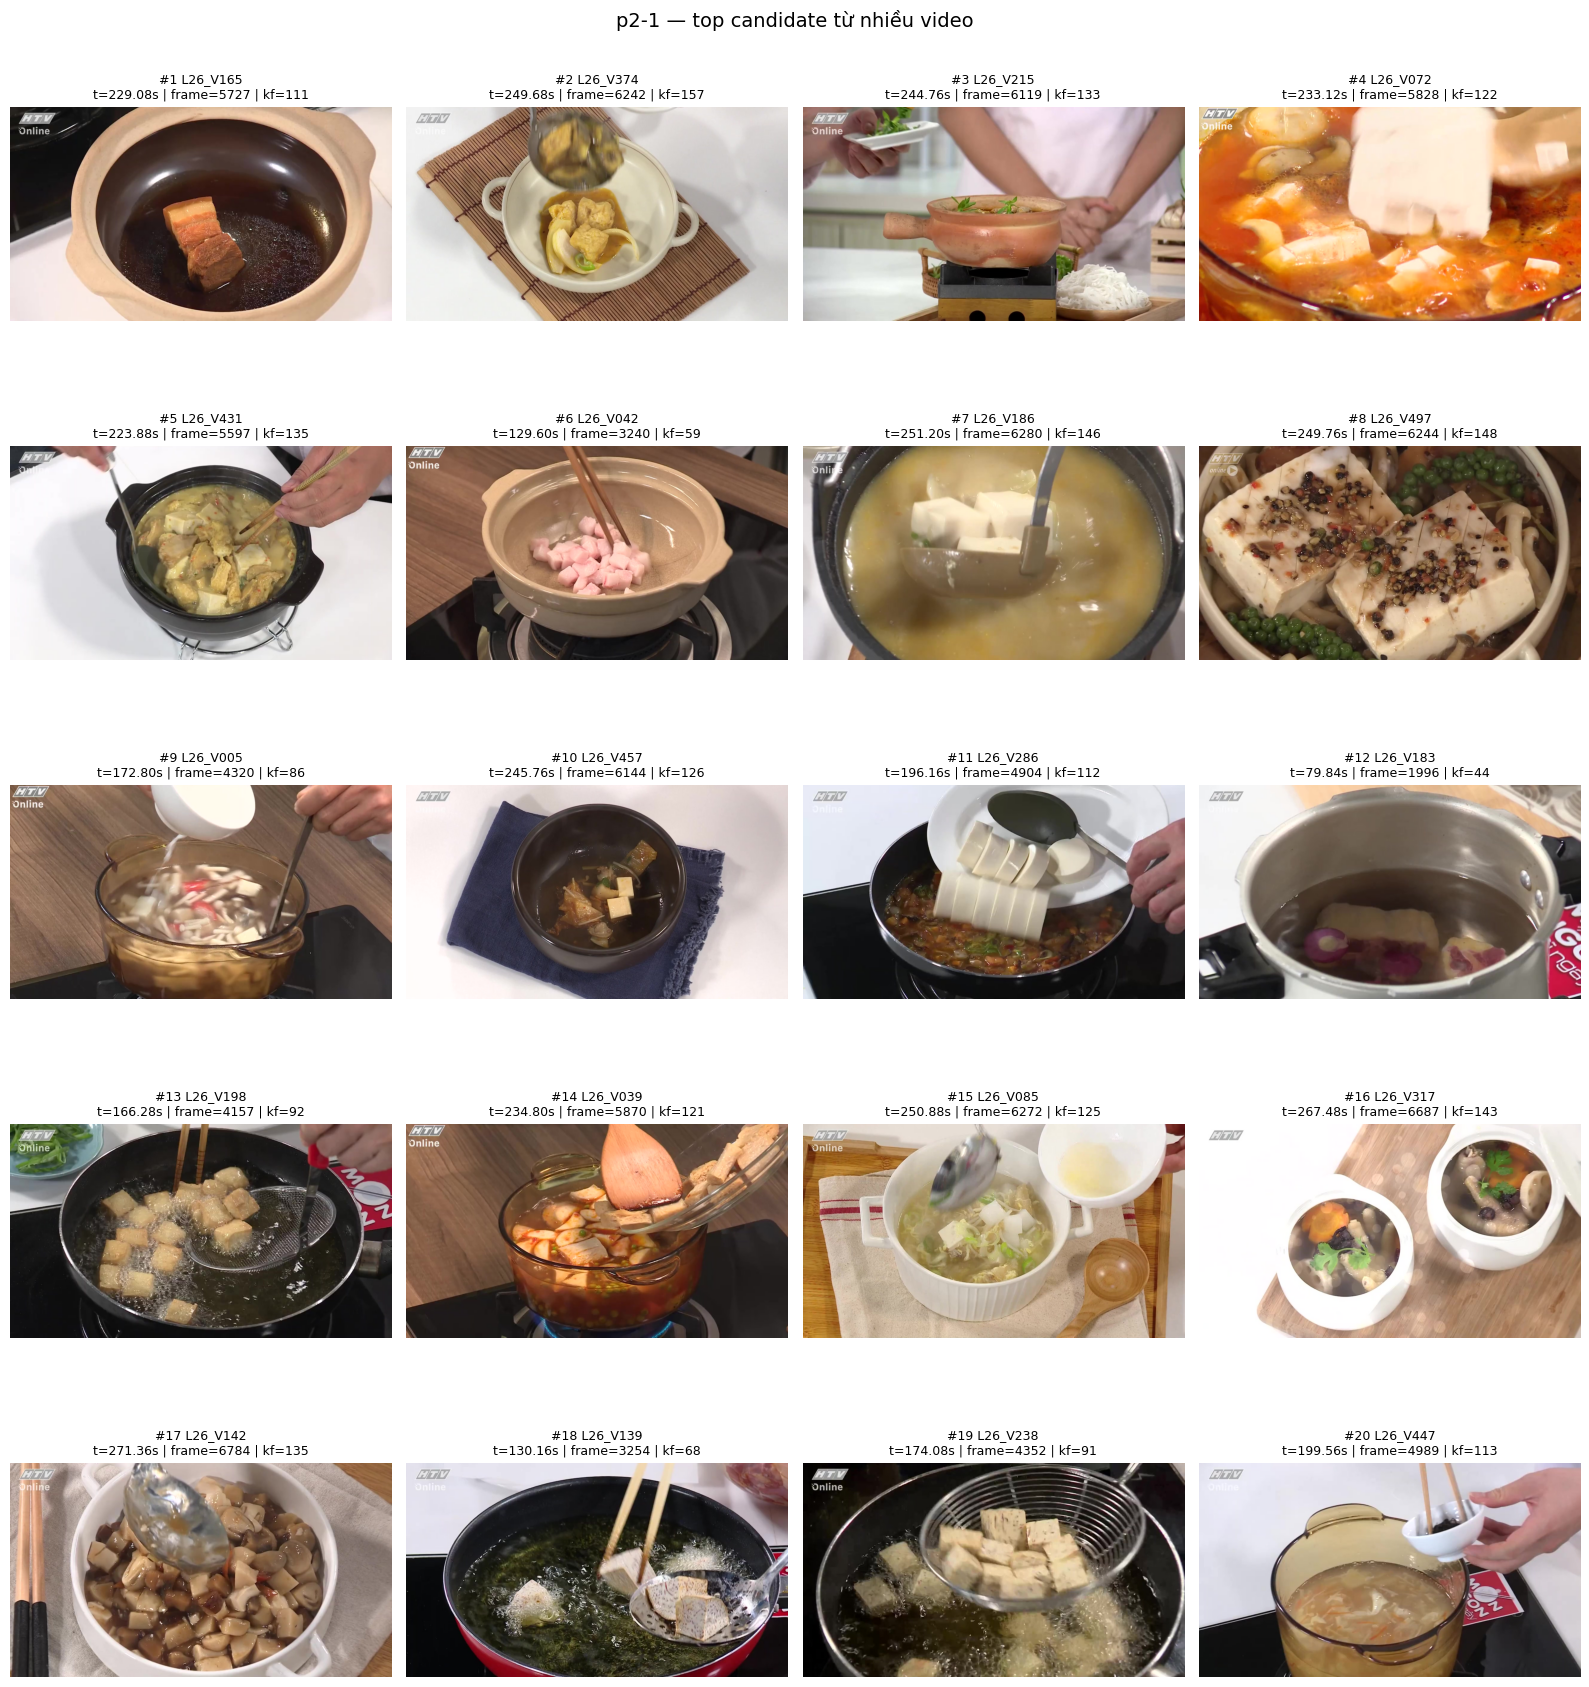

In [51]:
# 13c) Đọc ảnh trực tiếp trong ZIP keyframe — không giải nén toàn bộ
from PIL import Image
import matplotlib.pyplot as plt

_KEYFRAME_LOCATOR = {}
_KEYFRAME_MEMBERS = {}
_KEYFRAME_ARCHIVES = {}

def open_keyframe_archive(zip_path):
    key = str(Path(zip_path).resolve())
    if key not in _KEYFRAME_ARCHIVES:
        _KEYFRAME_ARCHIVES[key] = zipfile.ZipFile(zip_path)
    return _KEYFRAME_ARCHIVES[key]

def natural_number(name):
    stem = Path(name).stem
    match = re.search(r'(\d+)$', stem)
    return int(match.group(1)) if match else 10**12

def locate_keyframe_zip(video_id):
    if video_id in _KEYFRAME_LOCATOR:
        return _KEYFRAME_LOCATOR[video_id]
    group = video_id.split('_', 1)[0]
    candidates = sorted(KEYFRAME_ZIP_DIR.glob(f'Keyframes_{group}*.zip'))
    if not candidates:
        raise FileNotFoundError(f'Không thấy ZIP keyframe cho {group} tại {KEYFRAME_ZIP_DIR}')
    pattern = re.compile(rf'(^|/){re.escape(video_id)}/', re.IGNORECASE)
    for zip_path in candidates:
        archive = open_keyframe_archive(zip_path)
        if any(pattern.search(name.replace('\\', '/')) for name in archive.namelist()):
            _KEYFRAME_LOCATOR[video_id] = zip_path
            return zip_path
    raise FileNotFoundError(f'Không tìm thấy thư mục {video_id} trong ZIP {group}.')

def members_for_video(video_id):
    if video_id in _KEYFRAME_MEMBERS:
        return _KEYFRAME_MEMBERS[video_id]
    zip_path = locate_keyframe_zip(video_id)
    pattern = re.compile(
        rf'(^|/){re.escape(video_id)}/[^/]+\.(jpg|jpeg|png)$', re.IGNORECASE
    )
    archive = open_keyframe_archive(zip_path)
    members = [
        name for name in archive.namelist()
        if pattern.search(name.replace('\\', '/'))
    ]
    members = sorted(members, key=lambda name: (natural_number(name), name))
    expected = int((frame_metadata['video_id'] == video_id).sum())
    if len(members) != expected:
        raise RuntimeError(f'{video_id}: ZIP có {len(members)} ảnh nhưng metadata có {expected} dòng.')
    _KEYFRAME_MEMBERS[video_id] = (zip_path, members)
    return zip_path, members

def load_keyframe_image(video_id, npy_row):
    zip_path, members = members_for_video(video_id)
    position = int(npy_row)
    if not 0 <= position < len(members):
        raise IndexError(f'{video_id}: npy_row {position} ngoài 0..{len(members)-1}')
    archive = open_keyframe_archive(zip_path)
    with archive.open(members[position]) as source:
        return Image.open(io.BytesIO(source.read())).convert('RGB')

def show_frame_table(table, max_images=20, columns=4, title='Keyframe candidates'):
    table = table.head(int(max_images)).reset_index(drop=True)
    if table.empty:
        print('Không có ảnh để hiển thị.')
        return
    rows = int(np.ceil(len(table) / int(columns)))
    fig, axes = plt.subplots(rows, int(columns), figsize=(4 * int(columns), 3.6 * rows))
    axes = np.atleast_1d(axes).ravel()
    for axis, row in zip(axes, table.itertuples(index=False)):
        try:
            image = load_keyframe_image(row.video_id, row.npy_row)
            axis.imshow(image)
            axis.set_title(
                f'#{getattr(row, "rank", "?")} {row.video_id}\n'
                f't={float(row.pts_time):.2f}s | frame={int(row.frame_idx)} | kf={int(row.keyframe_n)}',
                fontsize=9,
            )
        except Exception as exc:
            axis.text(0.05, 0.5, f'{row.video_id}\n{exc}', wrap=True)
        axis.axis('off')
    for axis in axes[len(table):]:
        axis.axis('off')
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

def show_query_contact_sheet(query_id, max_images=20, columns=4):
    result = BATCH_RESULTS[query_id]
    show_frame_table(
        result['frames'], max_images=max_images, columns=columns,
        title=f'{query_id} — top candidate từ nhiều video',
    )

def show_candidate_full(query_id, rank=1, crop=None):
    table = BATCH_RESULTS[query_id]['frames']
    row = table.iloc[int(rank) - 1]
    image = load_keyframe_image(str(row.video_id), int(row.npy_row))
    if crop is not None:
        image = image.crop(tuple(map(int, crop)))
    print({
        'query_id': query_id,
        'rank': int(rank),
        'video_id': str(row.video_id),
        'frame_idx': int(row.frame_idx),
        'pts_time': float(row.pts_time),
        'keyframe_n': int(row.keyframe_n),
        'title': str(row.title),
    })
    display(image)
    return image

def ocr_candidate(query_id, rank=1, crop=None, lang='vie+eng', psm=6):
    try:
        import pytesseract
    except ImportError:
        subprocess.run(['pip', 'install', '-q', 'pytesseract'], check=True)
        import pytesseract
    required_languages = {item for item in str(lang).split('+') if item}
    installed_languages = set()
    if shutil.which('tesseract') is not None:
        try:
            installed_languages = set(pytesseract.get_languages(config=''))
        except Exception:
            installed_languages = set()
    if shutil.which('tesseract') is None or not required_languages.issubset(installed_languages):
        subprocess.run(['apt-get', '-qq', 'update'], check=True)
        packages = ['tesseract-ocr']
        if 'vie' in required_languages:
            packages.append('tesseract-ocr-vie')
        subprocess.run(['apt-get', '-qq', 'install', '-y', *packages], check=True)
    image = show_candidate_full(query_id, rank=rank, crop=crop)
    text = pytesseract.image_to_string(image, lang=lang, config=f'--psm {int(psm)}')
    print('OCR:\n', text)
    return text

def show_video_timeline(video_id, start_seconds=None, end_seconds=None, every=1, max_images=60, columns=5):
    table = frame_metadata[frame_metadata['video_id'] == video_id].sort_values('frame_idx').copy()
    if start_seconds is not None:
        table = table[table['pts_time'] >= float(start_seconds)]
    if end_seconds is not None:
        table = table[table['pts_time'] <= float(end_seconds)]
    table = table.iloc[::max(1, int(every))].head(int(max_images)).copy()
    table.insert(0, 'rank', np.arange(1, len(table) + 1))
    show_frame_table(table, max_images=max_images, columns=columns, title=f'{video_id} timeline')
    return table

# Mặc định hiển thị ngay 20 ảnh của câu đang review.
try:
    show_query_contact_sheet(REVIEW_QUERY_ID, max_images=20, columns=4)
except Exception as exc:
    print('⚠ Chưa hiển thị được keyframe:', exc)
    print('Kiểm tra 14 ZIP tại:', KEYFRAME_ZIP_DIR)

# Ví dụ sau khi chọn được video:
# show_video_timeline('L25_V001', start_seconds=0, end_seconds=30, every=1)
# show_candidate_full('p2-1', rank=1)
# ocr_candidate('p2-1', rank=1)  # crop=(x1, y1, x2, y2) nếu chỉ OCR bảng


### 13e) VLM verify candidates

Dùng Gemini để đánh giá nhanh top candidates. **Chỉ tham khảo**, không thay mắt người.

In [52]:
# 13e) VLM verify top candidates — HỖ TRỢ, không thay thế mắt người
# Dùng sau khi đã chạy batch retrieval và xem contact sheet.
# VLM đánh giá top 3 video/frame cho MỖI query, giúp bạn quyết định nhanh hơn.
#
# ⚠ VLM CÓ THỂ SAI, đặc biệt với:
#   - Đếm số lượng vật thể
#   - Text nhỏ / OCR tiếng Việt
#   - Phân biệt loài cá, rau, trái cây Việt Nam
#
# Kết quả VLM chỉ để THAM KHẢO. Bạn vẫn cần verify bằng keyframe + video.

if not VLM_ENABLED:
    print('⚠ VLM tắt. Bỏ qua cell này, dùng contact sheet (13c) để verify thủ công.')
elif not BATCH_RESULTS:
    print('⚠ Chưa chạy batch retrieval. Chạy cell 13 trước.')
else:
    from PIL import Image

    VERIFY_QUERY_ID = QUERY_IDS_ORDERED[0]  # ← Đổi query ID rồi chạy lại
    VERIFY_TOP_N = 3  # Verify top N video

    config = QUERY_BANK[VERIFY_QUERY_ID]
    result = BATCH_RESULTS[VERIFY_QUERY_ID]
    frames_df = result['frames']
    query_vi = config['query_vi']
    task = config['task']

    print(f'═══ VLM Verify: {VERIFY_QUERY_ID} [{task}] ═══')
    print(f'Query: {query_vi[:100]}...\n')

    # Lấy top-N video candidates
    seen_videos = []
    verify_rows = []
    for _, row in frames_df.iterrows():
        vid = row['video_id']
        if vid not in seen_videos:
            seen_videos.append(vid)
            verify_rows.append(row)
        if len(seen_videos) >= VERIFY_TOP_N:
            break

    for i, row in enumerate(verify_rows):
        vid = row['video_id']
        kf_n = int(row['keyframe_n'])
        frame_idx = int(row['frame_idx'])
        pts = float(row['pts_time'])

        # Dùng đúng npy_row và ZIP member index đã được cell 13c kiểm tra.
        try:
            img = load_keyframe_image(str(vid), int(row['npy_row']))
        except Exception as image_error:
            print(f'  [{i+1}] {vid} frame={frame_idx} — không đọc được ảnh: {image_error}')
            continue

        # Gọi VLM verify
        if task == 'kis':
            vlm_prompt = (
                f'Nhìn ảnh keyframe này. Mô tả video:\n"{query_vi}"\n\n'
                f'Ảnh này có khớp với mô tả không? '
                f'Trả lời: MATCH/PARTIAL/NO, confidence 0-100, lý do ngắn gọn.'
            )
        elif task == 'qa':
            question = config.get('question_vi', '')
            vlm_prompt = (
                f'Nhìn ảnh keyframe từ video.\nMô tả: "{query_vi}"\n'
                f'Câu hỏi: "{question}"\n\n'
                f'1) Ảnh có khớp mô tả? MATCH/PARTIAL/NO\n'
                f'2) Nếu MATCH, đáp án câu hỏi là gì?\n'
                f'3) Confidence 0-100'
            )
        else:  # trake
            vlm_prompt = (
                f'Nhìn ảnh keyframe. Mô tả video:\n"{query_vi}"\n\n'
                f'Ảnh này có thuộc video được mô tả không? MATCH/PARTIAL/NO, confidence 0-100.'
            )

        try:
            vlm_resp = vlm_client.models.generate_content(
                model=VLM_MODEL,
                contents=[vlm_prompt, img],
                config=genai_types.GenerateContentConfig(temperature=0.1),
            )
            verdict = vlm_resp.text.strip()
        except Exception as e:
            verdict = f'(VLM error: {e})'

        print(f'  [{i+1}] {vid} | kf={kf_n} frame_idx={frame_idx} pts={pts:.1f}s')
        print(f'      VLM: {verdict}')
        print()

    print('⚠ NHẮC: VLM chỉ tham khảo. Xem keyframe contact sheet (13c) và video (13d) để chốt.')


⚠ VLM tắt. Bỏ qua cell này, dùng contact sheet (13c) để verify thủ công.


### 13d) Video chính thức cho QA/TRAKE

Chỉ gọi `download_official_video(video_id)` sau khi đã rút xuống 1–3 video ứng viên.


In [53]:
# 13d) Tải CHỌN LỌC đúng một MP4 chính thức từ ZIP video qua HTTP Range
from remotezip import RemoteZip

VIDEO_ARCHIVES_BY_GROUP = {
    **{f'L{number}': [f'https://aic-data.ledo.io.vn/Videos_L{number}_a.zip'] for number in range(21, 31)},
    'L26': [f'https://aic-data.ledo.io.vn/Videos_L26_{part}.zip' for part in 'abcde'],
}
_REMOTE_VIDEO_LOCATOR = {}

def locate_official_video(video_id):
    if video_id in _REMOTE_VIDEO_LOCATOR:
        return _REMOTE_VIDEO_LOCATOR[video_id]
    group = video_id.split('_', 1)[0]
    urls = VIDEO_ARCHIVES_BY_GROUP.get(group, [])
    if not urls:
        raise KeyError(f'Không có archive cho group {group}')
    for url in urls:
        print('Kiểm tra central directory:', Path(url).name)
        with RemoteZip(url) as archive:
            members = [
                name for name in archive.namelist()
                if Path(name).stem.lower() == video_id.lower() and Path(name).suffix.lower() == '.mp4'
            ]
        if members:
            _REMOTE_VIDEO_LOCATOR[video_id] = (url, members[0])
            return url, members[0]
    raise FileNotFoundError(f'Không tìm thấy {video_id}.mp4 trong archive chính thức.')

def download_official_video(video_id, keep_on_drive=True):
    runtime_dir = WORK_DIR / 'selected_videos'
    runtime_dir.mkdir(parents=True, exist_ok=True)
    runtime_path = runtime_dir / f'{video_id}.mp4'
    drive_path = SELECTED_VIDEOS_DIR / f'{video_id}.mp4'
    if runtime_path.is_file() and runtime_path.stat().st_size > 0:
        return runtime_path
    if drive_path.is_file() and drive_path.stat().st_size > 0:
        print('→ Copy MP4 đã lưu trên Drive xuống runtime...')
        shutil.copy2(drive_path, runtime_path)
        return runtime_path
    url, member = locate_official_video(video_id)
    temporary = runtime_path.with_suffix('.mp4.part')
    print(f'↓ Trích riêng {member} từ {Path(url).name}...')
    with RemoteZip(url) as archive, archive.open(member) as source, open(temporary, 'wb') as output:
        shutil.copyfileobj(source, output, length=8 * 1024 * 1024)
    os.replace(temporary, runtime_path)
    if keep_on_drive:
        print('→ Lưu MP4 đã chọn lên Drive...')
        shutil.copy2(runtime_path, drive_path)
    print('✓', runtime_path, f'({runtime_path.stat().st_size / 2**20:.1f} MiB)')
    return runtime_path

def show_video_frame_window(video_id, center_frame, radius=60, step=10, columns=5):
    import cv2
    radius, step, columns = int(radius), int(step), int(columns)
    if radius < 0 or step <= 0 or columns <= 0:
        raise ValueError('radius >= 0, step > 0 và columns > 0.')
    video_path = download_official_video(video_id)
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise RuntimeError(f'Không mở được {video_path}')
    total = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        capture.release()
        raise RuntimeError(f'Video không có frame đọc được: {video_path}')
    requested_ids = list(range(
        max(0, int(center_frame) - radius),
        min(total, int(center_frame) + radius + 1),
        step,
    ))
    images = []
    for frame_id in requested_ids:
        capture.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
        ok, bgr = capture.read()
        if ok and bgr is not None:
            images.append((frame_id, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)))
    capture.release()
    if not images:
        raise RuntimeError(f'Không giải mã được frame nào quanh {center_frame} của {video_id}.')
    rows = int(np.ceil(len(images) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.3 * rows))
    axes = np.atleast_1d(axes).ravel()
    for axis, (frame_id, image) in zip(axes, images):
        axis.imshow(image)
        axis.set_title(f'frame_idx={frame_id}')
        axis.axis('off')
    for axis in axes[len(images):]:
        axis.axis('off')
    plt.tight_layout()
    plt.show()
    return [frame_id for frame_id, _ in images]

# Không tự tải video khi Run all. Sau khi chốt candidate, chạy ví dụ:
# path = download_official_video('L26_V001')
# show_video_frame_window('L26_V001', center_frame=12345, radius=90, step=10)
# Sau đó giảm step còn 2 hoặc 1 để chốt TRAKE.


## 14–15) Chốt đáp án và tạo submission

In [60]:
# 14) CẤU HÌNH REVIEW P3 — chỉ điền giá trị ĐÃ XÁC MINH
# ⚠ Đây là cell quan trọng nhất. Mỗi row override đúng ở rank 1 = cải thiện R@1,5,20,50,100.
# ⚠ KHÔNG bao giờ đưa row chưa verify lên override. Thà nộp batch draft còn hơn override sai.

# ── QA: đáp án người dùng cung cấp; p2-14 và p2-35 đang UNVERIFIED ──
# p2-14: người dùng đưa 3/4/5/6, tạm chọn phương án đầu là 3.
# p2-35: chưa có đáp án, tạm đoán 40 theo yêu cầu xuất gấp.
QA_ANSWERS = {
    'p2-5': '15',
    'p2-6': 'Tây Bắc',
    'p2-8': 'SEGA',
    'p2-14': '3',       # UNVERIFIED: lựa chọn đầu trong 3/4/5/6
    'p2-18': 'Tiểu học Công Hải',
    'p2-24': '2 muỗng',
    'p2-27': '3',
    'p2-35': '40',      # UNVERIFIED: phỏng đoán
}

# ── FINAL_ROWS_OVERRIDE: Row ĐÃ XÁC MINH đưa lên rank 1 ──
# KIS: ('video_id', frame_idx)
# QA:  ('video_id', frame_idx, 'answer')  — answer phải có trong QA_ANSWERS
# TRAKE: ('video_id', frame_E1, frame_E2, ..., frame_EN)  — frame tăng dần
FINAL_ROWS_OVERRIDE = {
    # 'p2-1':  [('L21_V003', 15240)],
    # 'p2-5':  [('L21_V003', 15240, '42')],
    # 'p2-21': [('L21_V005', 100, 200, 300, 400)],
}

# ── TRAKE: Dùng draft hay không? ──
# True = nộp chuỗi draft từ batch (kém hơn vì dựa trên sparse keyframes)
# False = CHỈ nộp override đã verify từ MP4 gốc (tốt hơn nếu đã verify)
USE_DRAFT_TRAKE_SEQUENCE = True

# ── Token xác nhận — cell 15 sẽ in token mới sau mỗi lần thay đổi config ──
FINAL_CONFIRMATION = 'AUTO_FINALIZE_NOW'  # chế độ khẩn cấp: tạo ZIP ngay khi chạy cell #15


In [61]:
# 15) Kiểm tra đúng CSV và đóng gói ZIP tách biệt khỏi P1
def _rows_to_lists(rows, columns):
    if rows is None:
        return []
    if isinstance(rows, pd.DataFrame):
        missing = set(columns) - set(rows.columns)
        if missing:
            raise ValueError(f'DataFrame thiếu cột: {sorted(missing)}')
        return [list(row) for row in rows[columns].itertuples(index=False, name=None)]
    return [list(row) for row in rows]

def _merge_verified_then_draft(verified_rows, draft_rows, limit=100):
    merged = []
    seen = set()
    for row in [*verified_rows, *draft_rows]:
        key = tuple(str(value).strip() for value in row)
        if key in seen:
            continue
        seen.add(key)
        merged.append(row)
        if len(merged) >= int(limit):
            break
    return merged

def rows_for_final_submission(query_id):
    if query_id not in BATCH_RESULTS:
        raise KeyError('Không có batch candidate trong RAM; hãy chạy cell #13 trước.')
    config = QUERY_BANK[query_id]
    task = config['task']
    result = BATCH_RESULTS[query_id]
    override = FINAL_ROWS_OVERRIDE.get(query_id, [])

    if task == 'kis':
        columns = ['video_id', 'frame_idx']
        verified = _rows_to_lists(override, columns)
        draft = _rows_to_lists(result['frames'][columns].head(100), columns)

    elif task == 'qa':
        columns = ['video_id', 'frame_idx', 'answer']
        verified = _rows_to_lists(override, columns)
        configured_answer = str(QA_ANSWERS.get(query_id, '')).strip()
        override_answers = {str(row[2]).strip() for row in verified if len(row) == 3 and str(row[2]).strip()}
        if len(override_answers) > 1:
            raise ValueError(f'{query_id}: các QA override có đáp án không đồng nhất.')
        if not configured_answer and override_answers:
            configured_answer = next(iter(override_answers))
        if not configured_answer:
            raise ValueError(f'{query_id}: chưa điền QA_ANSWERS.')
        if override_answers and override_answers != {configured_answer}:
            raise ValueError(f'{query_id}: QA_ANSWERS khác đáp án trong override.')
        verified = [[row[0], row[1], configured_answer] for row in verified]
        draft = result['frames'][['video_id', 'frame_idx']].head(100).copy()
        draft['answer'] = configured_answer
        draft = _rows_to_lists(draft, columns)

    else:
        event_columns = [f'frame_{name}' for name in config['events_en']]
        columns = ['video_id', *event_columns]
        verified = _rows_to_lists(override, columns)
        sequences = result['trake_sequences']
        if USE_DRAFT_TRAKE_SEQUENCE:
            if sequences is None or sequences.empty:
                if not verified:
                    raise ValueError(f'{query_id}: không có chuỗi TRAKE draft hoặc override.')
                draft = []
            else:
                draft = _rows_to_lists(sequences[columns].head(100), columns)
        else:
            if not verified:
                raise ValueError(f'{query_id}: cần FINAL_ROWS_OVERRIDE hoặc bật draft TRAKE.')
            draft = []

    merged = _merge_verified_then_draft(verified, draft, limit=100)
    source = 'VERIFIED_OVERRIDE_PLUS_DRAFT' if verified and draft else (
        'VERIFIED_OVERRIDE' if verified else (
            'TRAKE_DRAFT_UNVERIFIED' if task == 'trake' else
            'HYBRID_FRAME_WITH_MANUAL_ANSWER' if task == 'qa' else
            'HYBRID_UNVERIFIED'
        )
    )
    return merged, source

prepared_by_query = {}
finalization_problems = []
for query_id in QUERY_IDS_ORDERED:
    try:
        proposed_rows, row_source = rows_for_final_submission(query_id)
        task, cleaned_rows, expected_columns = prepare_submission_rows(query_id, proposed_rows)
        prepared_by_query[query_id] = {
            'task': task, 'rows': cleaned_rows, 'columns': expected_columns, 'source': row_source,
        }
    except Exception as error:
        finalization_problems.append({
            'query_id': query_id, 'problem': f'{type(error).__name__}: {error}',
        })

FINAL_SUBMISSION_ZIP = None
if finalization_problems:
    print('CHƯA TẠO ZIP — cần hoàn tất các mục sau:')
    display(pd.DataFrame(finalization_problems))
else:
    submission_payload = [
        {
            'query_id': query_id,
            'task': prepared_by_query[query_id]['task'],
            'rows': prepared_by_query[query_id]['rows'],
            'source': prepared_by_query[query_id]['source'],
        }
        for query_id in QUERY_IDS_ORDERED
    ]
    review_sha256 = hashlib.sha256(
        json.dumps(submission_payload, ensure_ascii=False, sort_keys=True, separators=(',', ':')).encode('utf-8')
    ).hexdigest()
    expected_confirmation = 'FINALIZE-' + review_sha256[:12].upper()
    review_table = pd.DataFrame([
        {
            'query_id': query_id,
            'task': prepared_by_query[query_id]['task'],
            'rows': len(prepared_by_query[query_id]['rows']),
            'source': prepared_by_query[query_id]['source'],
        }
        for query_id in QUERY_IDS_ORDERED
    ])
    display(review_table)
    print('Review SHA256:', review_sha256)
    auto_finalize_now = FINAL_CONFIRMATION == 'AUTO_FINALIZE_NOW'
    if FINAL_CONFIRMATION != expected_confirmation and not auto_finalize_now:
        print('\nCHƯA TẠO ZIP. Sau khi bảng đúng, dán token này vào FINAL_CONFIRMATION:')
        print(expected_confirmation)
    else:
        if auto_finalize_now:
            print('⚠ AUTO FINALIZE: p2-14 và p2-35 chứa đáp án chưa xác minh.')
        build_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + '-' + review_sha256[:12]
        local_build_dir = WORK_DIR / 'submission_builds_p3' / build_id
        local_submission_dir = local_build_dir / 'submission'
        local_submission_dir.mkdir(parents=True, exist_ok=False)
        expected_archive_names = []
        for query_id in QUERY_IDS_ORDERED:
            item = prepared_by_query[query_id]
            filename = f'query-{query_id}-{item["task"]}.csv'
            output_path = local_submission_dir / filename
            with open(output_path, 'w', encoding='utf-8', newline='') as file:
                csv.writer(file, delimiter=',', lineterminator='\n').writerows(item['rows'])
            validate_submission_file(query_id, output_path)
            expected_archive_names.append(f'submission/{filename}')

        local_zip = local_build_dir / 'submission.zip'
        with zipfile.ZipFile(local_zip, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
            for query_id in QUERY_IDS_ORDERED:
                item = prepared_by_query[query_id]
                filename = f'query-{query_id}-{item["task"]}.csv'
                archive.write(local_submission_dir / filename, arcname=f'submission/{filename}')
        with zipfile.ZipFile(local_zip) as archive:
            if archive.namelist() != expected_archive_names:
                raise RuntimeError('Tên/thứ tự file trong ZIP P3 không đúng.')
            if archive.testzip() is not None:
                raise RuntimeError('ZIP submission P3 bị lỗi CRC.')
            for query_id, archive_name in zip(QUERY_IDS_ORDERED, expected_archive_names):
                rows = list(csv.reader(io.StringIO(archive.read(archive_name).decode('utf-8'))))
                prepare_submission_rows(query_id, rows)

        final_dir = ROUND_SUBMISSION_ROOT / 'final'
        final_dir.mkdir(parents=True, exist_ok=True)
        drive_zip = final_dir / f'submission_p3_{build_id}.zip'
        drive_manifest = final_dir / f'submission_p3_{build_id}.manifest.json'
        shutil.copy2(local_zip, drive_zip)
        if sha256_file(local_zip) != sha256_file(drive_zip):
            raise RuntimeError('Checksum ZIP P3 trên Drive không khớp runtime.')
        final_manifest = {
            'build_id': build_id,
            'created_at_utc': datetime.now(timezone.utc).isoformat(),
            'batch_run_id': BATCH_RUN_ID,
            'review_sha256': review_sha256,
            'zip_sha256': sha256_file(drive_zip),
            'zip_path': str(drive_zip),
            'files': expected_archive_names,
            'rows': submission_payload,
        }
        with open(drive_manifest, 'w', encoding='utf-8', newline='\n') as file:
            json.dump(final_manifest, file, ensure_ascii=False, indent=2)
        FINAL_SUBMISSION_ZIP = drive_zip
        print('\nFINAL P3 SUBMISSION CREATED')
        print('ZIP:', drive_zip)
        print('SHA256:', final_manifest['zip_sha256'])
        print('Gồm CSV, không header, nằm trong thư mục submission/ của ZIP.')


,query_id,task,rows,source
0,p2-1,kis,100,HYBRID_UNVERIFIED
1,p2-2,kis,100,HYBRID_UNVERIFIED
2,p2-3,kis,100,HYBRID_UNVERIFIED
3,p2-4,kis,100,HYBRID_UNVERIFIED
4,p2-5,qa,100,HYBRID_FRAME_WITH_MANUAL_ANSWER
5,p2-6,qa,100,HYBRID_FRAME_WITH_MANUAL_ANSWER
6,p2-7,kis,100,HYBRID_UNVERIFIED
7,p2-8,qa,100,HYBRID_FRAME_WITH_MANUAL_ANSWER
8,p2-9,kis,100,HYBRID_UNVERIFIED
9,p2-10,kis,100,HYBRID_UNVERIFIED


Review SHA256: 7cb78d644546e1db995e3b8bfbadf96a29420cd477923d24dd805b00d63320bc
⚠ AUTO FINALIZE: p2-14 và p2-35 chứa đáp án chưa xác minh.

FINAL P3 SUBMISSION CREATED
ZIP: /content/drive/MyDrive/AIC2026/submission/p3/final/submission_p3_20260904T152513675272Z-7cb78d644546.zip
SHA256: f08e6286a876efe6b66f42227d5658d5990c0b5b60966c3b3f9a3adcc4933638
Gồm CSV, không header, nằm trong thư mục submission/ của ZIP.


## Thứ tự làm — tối ưu cho 3 tiếng thi

| Thời điểm | Việc | Cell |
|-----------|------|------|
| Ngay | Mở bản đã sửa trên Colab, chọn GPU và Run all; Gemini không bắt buộc. | `# 1` → `# 13` |
| +5 phút | Xác nhận inventory 36/36 và prompt bank không báo lỗi. | `# 6`, `# 9` |
| +10 phút | Chờ batch retrieval hoàn tất đủ 36 draft. | `# 13` |
| +15 phút | Ưu tiên review QA và TRAKE trước, sau đó KIS confidence thấp. | `# 13b`–`# 13e` |
| +15 phút | Xem contact sheet (13c) + VLM verify (13e) cho KIS | 13c, 13e |
| +30 phút | **QA**: đọc đáp án từ keyframe/VLM/video | 13c, 13d, 13e |
| +45 phút | **TRAKE**: xác định video đúng, download MP4, align events | 13d |
| +60 phút | Điền QA_ANSWERS + FINAL_ROWS_OVERRIDE | 14 |
| +70 phút | **NỘP LẦN 1** → xem score trên leaderboard | 15 |
| +90 phút | Sửa các query confidence thấp, verify thêm | 13b-13e |
| +120 phút | **NỘP LẦN 2** (cải thiện) | 15 |
| +170 phút | Kiểm tra cuối cùng, **NỘP LẦN 3** (final) | 15 |

**Nguyên tắc:**
- Row ĐÃ VERIFY ở rank 1 > 100 row draft chưa verify.
- Đa dạng video ở top ranks (pipeline đã làm) — không sửa.
- Prefix `p2-*` trong bộ P3 là tên chính thức của đề; tuyệt đối không đổi thành `p3-*`.
- Candidate batch là draft chưa xác minh; QA không được đoán nếu còn thời gian xem video.
- Nộp sớm để biết hướng tổng thể, NHƯNG không biết query nào sai.
- Lần nộp cuối cùng mới tính điểm chính thức.